# MBAX 6418 Assignment 4: Fine-Tuning, three approaches on Amazon Gift Cards reviews
Zero-shot and few-shot on the hosted model, and a QLoRA fine-tune of a small model, all on the same 300 test reviews.
Sections: S0 setup, S1 data, S2 prompts, S3 freeze check, S4 hosted predictions, S5 fine-tuning,
S6 saved-adapter inference, S7 pre-scoring checks, S8 RESULTS (reads saved files only), S9 consistency, S10 report.

In [1]:
# [S0] HELPERS (inlined from src/a4_helpers.py, unit-tested locally)
"""Helpers for MBAX 6418 Assignment 4 (pure Python plus numpy-free metrics).

Split builder, labels, prompt builders (provisional until Phase 2), strict label
parser, metrics, McNemar, prediction IO, adapter ZIP builder and verifier.
"""
import gzip
import hashlib
import json
import math
import os
import random
import re
import time
import urllib.error
import urllib.request
import uuid
import zipfile

LABELS = ["POSITIVE", "NEUTRAL", "NEGATIVE"]
CM_COLUMNS = LABELS + ["INVALID"]
PREDICTION_FIELDS = ["original_row", "filtered_index", "title", "text",
                     "reference_label", "prediction", "raw_response"]
ADAPTER_FILES = ["adapter_model.safetensors", "adapter_config.json"]

SYSTEM_PROMPT = ("You are an expert product review analyst. "
                 "Determine the sentiment each Amazon review expresses.")
USER_INSTRUCTION = ("Classify the sentiment of the review below as exactly one of: "
                    "POSITIVE, NEUTRAL, NEGATIVE. Reply with exactly one word, no explanation.")

MIN_TEXT_CHARS = 3
TRAIN_RANGE = (1000, 19999)
VAL_RANGE = (20000, 29999)
TEST_RANGE = (30000, 39999)
TRAIN_PER_CLASS = 300
EVAL_PER_CLASS = 100
TRAIN_SEED = 43
# One id per kernel start; stored with each hosted call so a resumed run shows which answers came from which session.
SESSION_ID = uuid.uuid4().hex


# ---------------------------------------------------------------- data

def read_gz_lines(path):
    """Yield (original_row, line) with 1-based physical line numbers; blank lines count."""
    with gzip.open(path, "rb") as f:
        for n, raw in enumerate(f, start=1):
            yield n, raw.decode("utf-8").rstrip("\n").rstrip("\r")


def label_from_rating(rating):
    if isinstance(rating, bool) or not isinstance(rating, (int, float)):
        raise ValueError(f"rating is not a number: {rating!r}")
    if isinstance(rating, float) and (math.isnan(rating) or rating != int(rating)):
        raise ValueError(f"rating is not a whole number: {rating!r}")
    r = int(rating)
    if r in (4, 5):
        return "POSITIVE"
    if r == 3:
        return "NEUTRAL"
    if r in (1, 2):
        return "NEGATIVE"
    raise ValueError(f"rating outside 1..5: {rating!r}")


def iter_survivors(lines):
    """lines: iterable of (original_row, line). Yields survivor dicts in file order."""
    idx = 0
    for row, line in lines:
        if not line.strip():
            continue
        rec = json.loads(line)
        text = rec.get("text")
        if text is None:
            text = ""
        if not isinstance(text, str):
            raise TypeError(f"row {row}: text is {type(text).__name__}, not str")
        if len(text.strip()) < MIN_TEXT_CHARS:
            continue
        title = rec.get("title")
        if title is None:
            title = ""
        if not isinstance(title, str):
            raise TypeError(f"row {row}: title is {type(title).__name__}, not str")
        rating = rec.get("rating")
        yield {"original_row": row, "filtered_index": idx, "title": title, "text": text,
               "rating": rating, "reference_label": label_from_rating(rating)}
        idx += 1


def build_splits(survivors):
    """Return {'train','val','test'} lists of records per PLAN 4.1."""
    survivors = list(survivors)
    by_idx_ok = [s for s in survivors]
    train_pool = {c: [s for s in by_idx_ok if TRAIN_RANGE[0] <= s["filtered_index"] <= TRAIN_RANGE[1]
                      and s["reference_label"] == c] for c in LABELS}
    for c in LABELS:
        if len(train_pool[c]) < TRAIN_PER_CLASS:
            raise ValueError(f"train pool for {c} has {len(train_pool[c])} < {TRAIN_PER_CLASS}")
    rng = random.Random(TRAIN_SEED)  # created once, used only here
    combined = []
    for c in LABELS:
        combined.extend(rng.sample(train_pool[c], TRAIN_PER_CLASS))
    rng.shuffle(combined)

    def first_per_class(lo, hi):
        out = []
        for c in LABELS:
            got = [s for s in by_idx_ok if lo <= s["filtered_index"] <= hi
                   and s["reference_label"] == c][:EVAL_PER_CLASS]
            if len(got) < EVAL_PER_CLASS:
                raise ValueError(f"range {lo}-{hi} class {c} has {len(got)} < {EVAL_PER_CLASS}")
            out.extend(got)
        return sorted(out, key=lambda s: s["filtered_index"])

    return {"train": combined, "val": first_per_class(*VAL_RANGE), "test": first_per_class(*TEST_RANGE)}


# ---------------------------------------------------------------- prompts (provisional, D-01/D-02 open)

def _user_turn(title, text):
    return f"{USER_INSTRUCTION}\n\nReview title: {title}\nReview text: {text}"


def build_messages_zero_shot(title, text):
    return [{"role": "system", "content": SYSTEM_PROMPT},
            {"role": "user", "content": _user_turn(title, text)}]


def build_messages_few_shot(title, text, examples):
    """examples: iterable of (title, text, label) in prompt order."""
    msgs = [{"role": "system", "content": SYSTEM_PROMPT}]
    for ex_title, ex_text, ex_label in examples:
        if ex_label not in LABELS:
            raise ValueError(f"few-shot label not allowed: {ex_label!r}")
        msgs.append({"role": "user", "content": _user_turn(ex_title, ex_text)})
        msgs.append({"role": "assistant", "content": ex_label})
    msgs.append({"role": "user", "content": _user_turn(title, text)})
    return msgs


def build_messages_fine_tuned(title, text, target=None):
    msgs = build_messages_zero_shot(title, text)
    if target is not None:
        if target not in LABELS:
            raise ValueError(f"training target not allowed: {target!r}")
        msgs.append({"role": "assistant", "content": target})
    return msgs


def build_prompt_for_record(rec):
    """Only title and text are read from the record."""
    return build_messages_zero_shot(rec["title"], rec["text"])


def instruction_hash(messages):
    """Hash of the system text and the instruction line of the first user turn."""
    sys_txt = messages[0]["content"]
    first_user = next(m["content"] for m in messages if m["role"] == "user")
    instr = first_user.split("\n\nReview title:", 1)[0]
    return hashlib.sha256(json.dumps([sys_txt, instr]).encode("utf-8")).hexdigest()


# ---------------------------------------------------------------- parsing and metrics

def parse_label(raw):
    if not isinstance(raw, str):
        return "INVALID"
    s = raw.strip().upper()
    return s if s in LABELS else "INVALID"


def confusion_matrix(refs, preds):
    if len(refs) != len(preds) or not refs:
        raise ValueError("refs and preds must be non-empty and equal length")
    cm = [[0] * len(CM_COLUMNS) for _ in LABELS]
    for r, p in zip(refs, preds):
        if r not in LABELS:
            raise ValueError(f"bad reference label {r!r}")
        if p not in CM_COLUMNS:
            raise ValueError(f"bad prediction {p!r}")
        cm[LABELS.index(r)][CM_COLUMNS.index(p)] += 1
    return cm


def normalize_rows(cm):
    out = []
    for row in cm:
        t = sum(row)
        out.append([v / t if t else 0.0 for v in row])
    return out


def compute_metrics(refs, preds):
    cm = confusion_matrix(refs, preds)
    per = {}
    pred_totals = [sum(cm[i][j] for i in range(3)) for j in range(3)]
    for i, c in enumerate(LABELS):
        n = sum(cm[i])
        tp = cm[i][i]
        rec = tp / n if n else 0.0
        prec = tp / pred_totals[i] if pred_totals[i] else 0.0
        f1 = 2 * prec * rec / (prec + rec) if (prec + rec) else 0.0
        per[c] = {"n": n, "correct": tp, "incorrect": n - tp, "predicted": pred_totals[i],
                  "precision": prec, "recall": rec, "f1": f1}
    correct = sum(v["correct"] for v in per.values())
    return {"per_class": per, "correct": correct, "incorrect": len(refs) - correct,
            "invalid": sum(row[3] for row in cm),
            "macro_f1": sum(v["f1"] for v in per.values()) / 3,
            "balanced_accuracy": sum(v["recall"] for v in per.values()) / 3,
            "confusion": cm}


def mcnemar_exact(b, c):
    from scipy.stats import binomtest
    from statsmodels.stats.contingency_tables import mcnemar
    n = b + c
    p_sm = float(mcnemar([[0, b], [c, 0]], exact=True).pvalue)
    # PLAN 4.6 cross-check: one-sided binomial tail doubled, capped at 1
    p_bin = 1.0 if n == 0 else min(1.0, 2 * float(
        binomtest(min(b, c), n, 0.5, alternative="less").pvalue))
    if not math.isclose(p_sm, p_bin, rel_tol=1e-9, abs_tol=1e-12):
        raise AssertionError(f"McNemar mismatch b={b} c={c}: statsmodels {p_sm} vs binomial {p_bin}")
    return {"b": b, "c": c, "p": p_sm, "p_statsmodels": p_sm, "p_binomial": p_bin}


def mcnemar_by_id(ref_by_id, pred1_by_id, pred2_by_id):
    """b = approach 1 correct and 2 wrong; c = 1 wrong and 2 correct. Aligned by id."""
    ids = set(ref_by_id)
    if set(pred1_by_id) != ids or set(pred2_by_id) != ids:
        raise ValueError("id sets differ between reference and predictions")
    b = c = 0
    for i in sorted(ids):
        ok1 = pred1_by_id[i] == ref_by_id[i]
        ok2 = pred2_by_id[i] == ref_by_id[i]
        b += ok1 and not ok2
        c += ok2 and not ok1
    return mcnemar_exact(b, c)


# ---------------------------------------------------------------- prediction IO and ZIP

def write_predictions(path, records):
    with open(path, "w", encoding="utf-8", newline="\n") as f:
        for r in records:
            if list(r.keys()) != PREDICTION_FIELDS:
                raise ValueError(f"fields must be exactly {PREDICTION_FIELDS}, got {list(r.keys())}")
            f.write(json.dumps(r, ensure_ascii=False, separators=(",", ":")).replace("\u2028", "\\u2028")
                    .replace("\u2029", "\\u2029") + "\n")


def read_predictions(path):
    with open(path, "r", encoding="utf-8", newline="") as f:
        return [json.loads(line) for line in f.read().split("\n") if line]


def build_adapter_zip(paths, out_path):
    names = sorted(os.path.basename(p) for p in paths)
    if names != sorted(ADAPTER_FILES):
        raise ValueError(f"adapter ZIP must contain exactly {ADAPTER_FILES}, got {names}")
    with zipfile.ZipFile(out_path, "w", zipfile.ZIP_DEFLATED) as z:
        for p in paths:
            z.write(p, arcname=os.path.basename(p))


def verify_adapter_zip(path):
    names = zipfile.ZipFile(path).namelist()
    if sorted(names) != sorted(ADAPTER_FILES):
        raise ValueError(f"ZIP namelist {names} != {ADAPTER_FILES}")
    return names


# ---------------------------------------------------------------- config hash

def canonical_json(obj):
    return json.dumps(obj, sort_keys=True, ensure_ascii=False, separators=(",", ":"))


def sha256_hex(text):
    return hashlib.sha256(text.encode("utf-8")).hexdigest()


def config_hash(cfg):
    return sha256_hex(canonical_json(cfg))


def frozen_hash(cfg, keys):
    return config_hash({k: cfg[k] for k in keys})


def messages_hash(messages):
    return config_hash(messages)


# ---------------------------------------------------------------- hosted calls

class TransportError(Exception):
    pass


def http_post_json(url, body, api_key, timeout):
    """POST JSON. Returns (status, raw_text). Raises TransportError on network failure or timeout."""
    req = urllib.request.Request(url, method="POST", data=json.dumps(body).encode("utf-8"),
                                 headers={"Authorization": "Bearer " + api_key, "Content-Type": "application/json"})
    try:
        with urllib.request.urlopen(req, timeout=timeout) as r:
            return r.status, r.read().decode("utf-8")
    except urllib.error.HTTPError as e:
        return e.code, e.read().decode("utf-8", "replace")
    except (urllib.error.URLError, TimeoutError, ConnectionError, OSError) as e:
        raise TransportError(f"{type(e).__name__}: {e}") from None


def _hosted_body(messages, cfg):
    return {"model": cfg["model"], "messages": messages, "temperature": cfg["temperature"],
            "max_tokens": cfg["max_tokens"], **cfg.get("extra_body", {})}


CACHE_WRITE_ATTEMPTS = 6


def _write_cache_file(path, rec, sleep=time.sleep):
    """Atomic cache write that survives a flaky (Drive-backed) folder.

    The hosted answer is already in memory, so a failed tmp-to-final rename is retried by rewriting the tmp file;
    the API is never called again for it. After the last attempt the error is raised, never swallowed.
    """
    for attempt in range(1, CACHE_WRITE_ATTEMPTS + 1):
        tmp = f"{path}.{uuid.uuid4().hex[:8]}.tmp"
        try:
            os.makedirs(os.path.dirname(path), exist_ok=True)
            with open(tmp, "w", encoding="utf-8") as f:
                json.dump(rec, f, ensure_ascii=False)
                f.flush()
                os.fsync(f.fileno())
            os.replace(tmp, path)
            return
        except OSError:
            try:
                os.remove(tmp)
            except OSError:
                pass
            if attempt == CACHE_WRITE_ATTEMPTS:
                raise
            sleep(0.5 * attempt)


def call_hosted(messages, cfg, api_key, cache_dir, frozen, post=http_post_json, sleep=time.sleep):
    """One hosted chat call. Retries only transport errors and HTTP 5xx; never retries on content.

    The cache is keyed by sha256(frozen config hash + messages). First successful response wins.
    The API key is used only for the request header and is never stored.
    """
    os.makedirs(cache_dir, exist_ok=True)
    mh = messages_hash(messages)
    key = sha256_hex(frozen + "\n" + mh)
    path = os.path.join(cache_dir, key + ".json")
    if os.path.exists(path):
        with open(path, "r", encoding="utf-8") as f:
            rec = json.load(f)
        rec["from_cache"] = True
        return rec
    body = _hosted_body(messages, cfg)
    url = cfg["base_url"].rstrip("/") + "/chat/completions"
    attempts = 0
    while True:
        attempts += 1
        t0 = time.perf_counter()
        try:
            status, raw = post(url, body, api_key, cfg["timeout_s"])
        except TransportError:
            if attempts > cfg["max_retries"]:
                raise
            sleep(cfg["retry_backoff_s"] * attempts)
            continue
        latency = time.perf_counter() - t0
        if status >= 500:
            if attempts > cfg["max_retries"]:
                raise RuntimeError(f"HTTP {status} after {attempts} attempts")
            sleep(cfg["retry_backoff_s"] * attempts)
            continue
        if status >= 400:
            raise RuntimeError(f"HTTP {status}: {raw[:200]}")
        break
    resp = json.loads(raw)
    choice = resp["choices"][0]
    msg = choice["message"]
    content = msg.get("content")
    reasoning = msg.get("reasoning") or msg.get("reasoning_content")
    usage = resp.get("usage") or {}
    rtok = (usage.get("completion_tokens_details") or {}).get("reasoning_tokens") or 0
    violations = []
    if choice.get("finish_reason") != "stop":
        violations.append(f"finish_reason:{choice.get('finish_reason')}")
    if reasoning:
        violations.append("reasoning_present")
    if rtok:
        violations.append(f"reasoning_tokens:{rtok}")
    rec = {"key": key, "messages_sha256": mh, "request_body": body, "raw": raw, "latency_s": latency,
           "http_status": status, "attempts": attempts, "content": content,
           "finish_reason": choice.get("finish_reason"), "completion_tokens": usage.get("completion_tokens"),
           "violations": violations, "prediction": parse_label(content), "from_cache": False,
           "session_id": SESSION_ID, "created_utc": time.time()}
    _write_cache_file(path, rec, sleep)
    return rec


# ---------------------------------------------------------------- data and prompt checks (each raises)

def fewshot_examples(train_by_id, ids):
    out = []
    for i in ids:
        r = train_by_id[i]
        out.append((r["title"], r["text"], r["reference_label"]))
    return out


def check_training_examples(examples, train_source, per_class=300):
    """C-11: the objects handed to the trainer are exactly the prescribed training rows."""
    src = {r["filtered_index"]: r for r in train_source}
    ids = [e["filtered_index"] for e in examples]
    assert len(ids) == len(set(ids)), "duplicate ids in training examples"
    assert set(ids) == set(src), "training example ids differ from the prescribed training ids"
    assert len(ids) == 3 * per_class, f"expected {3 * per_class} examples, got {len(ids)}"
    counts = {c: 0 for c in LABELS}
    for e in examples:
        assert set(e.keys()) == {"filtered_index", "messages"}, f"unexpected fields {sorted(e.keys())}"
        r = src[e["filtered_index"]]
        expected = build_messages_fine_tuned(r["title"], r["text"], target=r["reference_label"])
        assert e["messages"] == expected, f"messages differ from source for id {e['filtered_index']}"
        counts[r["reference_label"]] += 1
    assert all(v == per_class for v in counts.values()), f"class counts {counts}"
    return counts


def check_fewshot(ids, train_ids, reserved_ids, prompt_messages, train_by_id):
    """C-12: few-shot ids are train rows, disjoint from reserved sets, and match the prompt turns."""
    assert set(ids) <= set(train_ids), "few-shot id not in train"
    assert not (set(ids) & set(reserved_ids)), "few-shot id overlaps reserved ids"
    exs = fewshot_examples(train_by_id, ids)
    turns = build_messages_few_shot("", "", exs)[1:-1]
    assert len(prompt_messages) == len(turns) + 2, "prompt has the wrong number of turns"
    assert prompt_messages[1:-1] == turns, "few-shot turns in the prompt differ from the train records"


def check_one_prediction_per_id(preds_by_approach, test_ids):
    """C-13."""
    want = list(test_ids)
    for name, recs in preds_by_approach.items():
        got = [r["filtered_index"] for r in recs]
        assert len(got) == len(set(got)), f"{name}: duplicate ids"
        assert set(got) == set(want), f"{name}: id set differs from the test ids"
        assert len(got) == len(want), f"{name}: wrong count {len(got)}"


def check_instruction_identity(zero_shot, few_shot, fine_tuned):
    """C-14b."""
    hs = {instruction_hash(m) for m in (zero_shot, few_shot, fine_tuned)}
    assert len(hs) == 1, "instruction text differs across approaches"


def check_prompt_inputs(record, messages):
    """C-15: a built prompt contains only title and text from the record."""
    assert messages == build_messages_zero_shot(record["title"], record["text"]), "prompt is not a pure function of title and text"


def check_no_truncation(lengths, max_seq_length):
    """C-16."""
    assert max(lengths) <= max_seq_length, f"longest example {max(lengths)} > max_seq_length {max_seq_length}"


def check_predictions_records(records, test_ids):
    """C-19."""
    assert len(records) == len(test_ids), f"expected {len(test_ids)} rows, got {len(records)}"
    assert len({r["filtered_index"] for r in records}) == len(records), "duplicate ids"
    assert {r["filtered_index"] for r in records} == set(test_ids), "ids differ from the test ids"
    for r in records:
        assert list(r.keys()) == PREDICTION_FIELDS, f"field order {list(r.keys())}"
        assert r["prediction"] in LABELS + ["INVALID"], f"bad prediction {r['prediction']!r}"
        assert r["prediction"] == parse_label(r["raw_response"]), "prediction does not follow raw_response"
        assert r["reference_label"] in LABELS


def check_prompt_examples(records, expected_messages_by_id):
    """C-20: 3 rows, one per class, messages equal the rebuilt prompt, no label inside messages."""
    assert len(records) == 3, f"expected 3 rows, got {len(records)}"
    assert sorted(r["reference_label"] for r in records) == sorted(LABELS), "not one row per class"
    for r in records:
        assert r["messages"] == expected_messages_by_id[r["filtered_index"]], "messages differ from rebuilt prompt"
        assert all(m["role"] != "assistant" for m in r["messages"]), "assistant turn (label) inside messages"


def scan_forbidden_tokens(sources, patterns):
    """Static scan used for C-07 and the sealed test labels: raise if any pattern occurs."""
    for i, src in enumerate(sources):
        for pat in patterns:
            m = re.search(pat, src)
            assert not m, f"forbidden pattern {pat!r} in source {i} near: {src[max(0, m.start() - 30):m.end() + 30]!r}"


# ---------------------------------------------------------------- in-notebook data checks C-02..C-10

def read_zip_splits(zip_path):
    with zipfile.ZipFile(zip_path) as z:
        return {k: [json.loads(x) for x in z.read(f"{k}.jsonl").decode("utf-8").split("\n") if x.strip()]
                for k in ("train", "val", "test")}


def run_data_checks(survivors, splits, zipped):
    """Port of tools/check_data.py (C-02..C-10). Returns a list of result dicts; raises on any failure."""
    fields = ["original_row", "filtered_index", "title", "text", "rating", "reference_label"]
    res = []

    def check(cid, ok, detail):
        res.append({"id": cid, "pass": bool(ok), "detail": detail})

    check("C-02", all({(r["filtered_index"], r["original_row"]) for r in splits[k]} ==
                      {(r["filtered_index"], r["original_row"]) for r in zipped[k]} for k in splits),
          "(filtered_index, original_row) pairs equal the zip for train, val, test")
    mism = 0
    for k in splits:
        zr = {r["filtered_index"]: r for r in zipped[k]}
        for r in splits[k]:
            z = zr[r["filtered_index"]]
            mism += any(r[f] != z[f] for f in fields)
    check("C-02b", mism == 0, f"records with a field mismatch vs zip: {mism}")
    bad = sum(label_from_rating(r["rating"]) != r["reference_label"] for k in splits for r in zipped[k] + splits[k])
    check("C-03", bad == 0, f"label/rating mismatches: {bad}")
    rng = {"train": TRAIN_RANGE, "val": VAL_RANGE, "test": TEST_RANGE}
    check("C-04", all(rng[k][0] <= r["filtered_index"] <= rng[k][1] for k in rng for r in zipped[k] + splits[k]),
          f"ranges {rng}")
    check("C-05", [r["filtered_index"] for r in splits["train"]] == [r["filtered_index"] for r in zipped["train"]],
          "train records and ORDER reproduced from Random(43)")
    for cid, k, (lo, hi) in (("C-06", "test", TEST_RANGE), ("C-07a", "val", VAL_RANGE)):
        want = set()
        for c in LABELS:
            want |= set([s["filtered_index"] for s in survivors if lo <= s["filtered_index"] <= hi
                         and s["reference_label"] == c][:EVAL_PER_CLASS])
        check(cid, want == {r["filtered_index"] for r in zipped[k]}, f"{k} = first {EVAL_PER_CLASS} per class in file order")
    ok = True
    parts = []
    for k, n in (("train", TRAIN_PER_CLASS), ("val", EVAL_PER_CLASS), ("test", EVAL_PER_CLASS)):
        for name, src in (("zip", zipped[k]), ("rebuilt", splits[k])):
            cnt = {c: sum(r["reference_label"] == c for r in src) for c in LABELS}
            ok &= len(src) == 3 * n and all(v == n for v in cnt.values())
            parts.append(f"{k}/{name}: n={len(src)} {cnt}")
    check("C-08", ok, "; ".join(parts))
    check("C-09", all(len({r["filtered_index"] for r in s}) == len(s) and len({r["original_row"] for r in s}) == len(s)
                      for s in list(zipped.values()) + list(splits.values())), "unique ids within each set")
    ids = {k: {r["filtered_index"] for r in splits[k]} for k in splits}
    ov = {f"{a}&{b}": len(ids[a] & ids[b]) for a, b in (("train", "val"), ("train", "test"), ("val", "test"))}
    check("C-10", all(v == 0 for v in ov.values()), f"overlaps {ov}")
    failed = [r["id"] for r in res if not r["pass"]]
    assert not failed, f"data checks failed: {failed}"
    return res


# ---------------------------------------------------------------- results helpers (S8)

def best_approach(metrics_by_name):
    """Highest macro-F1; tie-break higher balanced accuracy, then alphabetical name (declared in PLAN 4.6)."""
    return sorted(metrics_by_name, key=lambda n: (-metrics_by_name[n]["macro_f1"],
                                                  -metrics_by_name[n]["balanced_accuracy"], n))[0]


def error_analysis(ref_by_id, zero_by_id, few_by_id, ft_by_id, n=10):
    """First n ids (by filtered_index) in each list. Rule fixed in advance (DEC-07)."""
    ids = sorted(ref_by_id)

    def ok(pred, i):
        return pred[i] == ref_by_id[i]

    fixed = [i for i in ids if ok(ft_by_id, i) and not ok(zero_by_id, i) and not ok(few_by_id, i)]
    broken = [i for i in ids if not ok(ft_by_id, i) and ok(zero_by_id, i) and ok(few_by_id, i)]
    wrong_all = [i for i in ids if not ok(ft_by_id, i) and not ok(zero_by_id, i) and not ok(few_by_id, i)]
    return {"fixed_by_ft": {"total": len(fixed), "ids": fixed[:n]},
            "broken_by_ft": {"total": len(broken), "ids": broken[:n]},
            "wrong_in_all": {"total": len(wrong_all), "ids": wrong_all[:n]}}


# Phase 2 rule (tools/phase2_shortlist.py), reused for the optional title-leakage analysis.
STAR_TITLE = re.compile(r"^\s*(\w+\s+)?(\d|one|two|three|four|five)\s+stars?\b", re.I)


def is_star_title(title):
    return bool(STAR_TITLE.match(title or ""))


def star_title_breakdown(ref_by_id, title_by_id, preds_by_name):
    """Descriptive only: correct counts on star-word titles vs the other titles, overall and within each reference
    class (the class mix differs between the two groups). INVALID counts as wrong. Never used to tune."""
    ids = sorted(ref_by_id)
    star = [i for i in ids if is_star_title(title_by_id[i])]
    rest = [i for i in ids if not is_star_title(title_by_id[i])]

    def mix(sub):
        return {c: sum(ref_by_id[i] == c for i in sub) for c in LABELS}

    def acc(pred, sub):
        n_ok = sum(pred[i] == ref_by_id[i] for i in sub)
        return n_ok, (n_ok / len(sub) if sub else None)

    by = {}
    for n in sorted(preds_by_name):
        p = preds_by_name[n]
        sc, sa = acc(p, star)
        rc, ra = acc(p, rest)
        per = {}
        for c in LABELS:
            s_c, r_c = [i for i in star if ref_by_id[i] == c], [i for i in rest if ref_by_id[i] == c]
            (s_ok, s_rec), (r_ok, r_rec) = acc(p, s_c), acc(p, r_c)
            per[c] = {"star_n": len(s_c), "star_correct": s_ok, "star_recall": s_rec,
                      "rest_n": len(r_c), "rest_correct": r_ok, "rest_recall": r_rec}
        by[n] = {"star_correct": sc, "star_accuracy": sa, "rest_correct": rc, "rest_accuracy": ra, "per_class": per}
    return {"n_star": len(star), "n_rest": len(rest), "star_ids": star,
            "star_label_mix": mix(star), "rest_label_mix": mix(rest), "by_approach": by}


def flip_sample(train_rows, exclude_ids, per_class, seed):
    """DEC-05: per_class TRAIN ids per class (exclusions removed), one RNG over classes in LABELS order, sorted output."""
    rng = random.Random(seed)
    excl = set(exclude_ids)
    out = []
    for c in LABELS:
        pool = sorted(r["filtered_index"] for r in train_rows if r["reference_label"] == c and r["filtered_index"] not in excl)
        assert len(pool) >= per_class, f"flip sample: only {len(pool)} {c} rows"
        out += rng.sample(pool, per_class)
    return sorted(out)


def repeat_hosted(messages, cfg, api_key, cache_root, frozen, repeats, post=http_post_json, sleep=time.sleep):
    """DEC-05: `repeats` independent calls for one prompt. Each repeat has its own cache folder, so the calls are
    separate requests, while a restart resumes from saved responses instead of re-rolling them."""
    return [call_hosted(messages, cfg, api_key, os.path.join(cache_root, f"rep{k}"), frozen, post=post, sleep=sleep)
            for k in range(1, repeats + 1)]


def flip_rate(reps_by_id):
    """reps_by_id: id -> list of (prediction, raw content), one per repeat. A flip = not all repeats identical."""
    counts = {len(v) for v in reps_by_id.values()}
    assert len(counts) <= 1, f"uneven repeats: {counts}"
    ids = sorted(reps_by_id)
    label_flips = [i for i in ids if len({p for p, _ in reps_by_id[i]}) > 1]
    raw_flips = [i for i in ids if len({r for _, r in reps_by_id[i]}) > 1]
    return {"items": len(ids), "repeats": counts.pop() if counts else 0, "label_flips": len(label_flips),
            "label_flip_ids": label_flips, "label_flip_rate": len(label_flips) / len(ids) if ids else None, "raw_flips": len(raw_flips), "raw_flip_ids": raw_flips,
            "invalid_responses": sum(p == "INVALID" for v in reps_by_id.values() for p, _ in v)}


def flip_summary(raw_records, approaches):
    """DEC-05 result rebuilt from the saved flip records (S4b writes them, S10 re-reads them after any restart).
    mixed_session_ids: prompts whose repeats were answered in different kernel sessions (a resumed run)."""
    out = {}
    for a in approaches:
        recs = [r for r in raw_records if r["approach"] == a]
        ids = sorted({r["filtered_index"] for r in recs})
        reps, sessions = {}, {}
        for i in ids:
            rs = sorted((r for r in recs if r["filtered_index"] == i), key=lambda r: r["repeat"])
            assert [r["repeat"] for r in rs] == list(range(1, len(rs) + 1)), f"{a} id {i}: repeats {[r['repeat'] for r in rs]}"
            reps[i] = [(r["prediction"], r["raw_response"]) for r in rs]
            sessions[i] = {r["session_id"] for r in rs}
        res = flip_rate(reps)
        res.update({"calls": len(recs), "cache_hits": sum(bool(r["from_cache"]) for r in recs),
                    "calls_with_violations": sum(bool(r["violations"]) for r in recs),
                    "sum_latency_s": round(sum(r["latency_s"] for r in recs), 3),
                    "mixed_session_ids": [i for i in ids if len(sessions[i]) > 1]})
        out[a] = res
    return out


def pairwise_mcnemar(ref_by_id, preds_by_name):
    names = sorted(preds_by_name)
    out = {}
    for i, a in enumerate(names):
        for b in names[i + 1:]:
            out[f"{a} vs {b}"] = mcnemar_by_id(ref_by_id, preds_by_name[a], preds_by_name[b])
    return out


# ---------------------------------------------------------------- chat text for training, prefix check, canonical prompts

def render_chat_text(tok, messages, strip_bos=True):
    """Chat-template text for training. Some templates emit BOS as text while the tokenizer adds BOS again."""
    t = tok.apply_chat_template(messages, tokenize=False)
    if strip_bos and getattr(tok, "bos_token", None) and t.startswith(tok.bos_token):
        t = t[len(tok.bos_token):]
    return t


def check_prompt_is_training_prefix(prompt_ids, train_ids):
    """R-19: the token ids of the inference prompt are exactly the start of the training example's ids (single BOS)."""
    prompt_ids, train_ids = list(prompt_ids), list(train_ids)
    assert len(prompt_ids) < len(train_ids), "training example is not longer than its prompt"
    assert train_ids[:len(prompt_ids)] == prompt_ids, "inference prompt tokens are not a prefix of the training tokens"


def canonical_prompt_fingerprint(fewshot):
    """Rendered prompts for fixed synthetic inputs plus the parser table, so any drift in the helpers changes the freeze hash."""
    probe = ["POSITIVE", " neutral\n", "Positive.", "", "POSITIVE NEGATIVE", None]
    return {"zero_shot": build_messages_zero_shot(" T ", "Line1\nLine2 "),
            "few_shot": build_messages_few_shot(" T ", "Line1\nLine2 ", fewshot),
            "fine_tuned": build_messages_fine_tuned(" T ", "Line1\nLine2 ", target="NEUTRAL"),
            "parse_table": [parse_label(x) for x in probe]}


In [2]:
import importlib.metadata as _md
import json, math, os, subprocess, sys, time

MODE = "final"  # "dryrun": plumbing on TRAIN rows only, never the test set. "final": the single full run.
USE_DRIVE = True  # final run: True, to copy artifacts to Google Drive after each long step

OUT = "/content/a4_out"
CACHE_DIR = OUT + "/hosted_cache"
os.makedirs(OUT, exist_ok=True)

CONFIG = {
    "prompt": {"system": SYSTEM_PROMPT, "instruction": USER_INSTRUCTION},
    "hosted": {"base_url": "http://dobolyi.com:9001/v1", "model": "cyankiwi/Qwen3.6-35B-A3B-AWQ-4bit",
               "temperature": 0, "max_tokens": 8, "extra_body": {"chat_template_kwargs": {"enable_thinking": False}},
               "timeout_s": 120, "max_retries": 3, "retry_backoff_s": 2},
    "fewshot_ids": [13547, 16202, 11866, 2749, 9272, 9440],
    # D-05 re-decided (DEC-11): Gemma 3 4B. google/gemma-3-4b-it is gated, so the ungated Unsloth copy of the same
    # weights is loaded and quantized to 4-bit on load (the recorded base id will be this copy, see DEC-12).
    "small_model": {"load_id": "unsloth/gemma-3-4b-it", "load_in_4bit": True, "max_seq_length": 512,
                    "max_new_tokens": 8, "batch_size": 1, "do_sample": False, "skip_special_tokens": True,
                    "instruction_part": "<start_of_turn>user\n", "response_part": "<start_of_turn>model\n",
                    "strip_bos_from_text": True,
                    # C-28: hub revisions seen in the dry run (2026-10-26); the run stops if either changed.
                    "expected_revisions": {"unsloth/gemma-3-4b-it": "bf46152c47f5dd20b896357cb51abc4c03b8ee8c",
                                           "unsloth/gemma-3-4b-it-unsloth-bnb-4bit": "316726ca0bd24aa323bfaf86e8a379ee1176d1fe"},
                    # DEC-12 (pending): id that must appear in adapter_config.json. adapter_base_id_override None keeps
                    # what Unsloth writes; a string rewrites the field openly (printed) before the ZIP is built.
                    "adapter_base_id_override": None,
                    "expected_adapter_base_id": "unsloth/gemma-3-4b-it-unsloth-bnb-4bit"},
    "train": {"r": 16, "lora_alpha": 16, "lora_dropout": 0, "bias": "none",
              "finetune_vision_layers": False, "finetune_language_layers": True,
              "finetune_attention_modules": True, "finetune_mlp_modules": True,
              "expected_lora_modules": ["q_proj", "k_proj", "v_proj", "o_proj", "gate_proj", "up_proj", "down_proj"],
              "learning_rate": 2e-4, "weight_decay": 0.01, "lr_scheduler_type": "linear", "warmup_steps": 5,
              "per_device_train_batch_size": 2, "gradient_accumulation_steps": 8, "num_train_epochs": 2,
              "optim": "adamw_8bit", "seed": 3407, "use_gradient_checkpointing": "unsloth", "packing": False},
    # DEC-05 (a plus b): hosted flip rate on TRAIN reviews only, separate from the reported results.
    "flip_rate": {"seed": 20261029, "per_class": 10, "repeats": 3, "approaches": ["zero_shot", "few_shot"]},
}
SM = CONFIG["small_model"]
TR = CONFIG["train"]
FROZEN_KEYS = ["prompt", "hosted", "fewshot_ids", "small_model", "train", "flip_rate"]
# Run-specific values are NOT frozen (they differ between dry run and final run).
# flip_items_per_class: the dry run sends 1 review per class (18 calls) to test plumbing; the final run sends all 30.
RUN = {"mode": MODE, "smoke_max_steps": 10 if MODE == "dryrun" else -1, "workers": 4,
       "flip_items_per_class": 1 if MODE == "dryrun" else CONFIG["flip_rate"]["per_class"]}
APPROVED_FREEZE_HASH = "8a1f06f40c4f3f273bd8149f7b4c25a9c0b20005ae5b5b435ae51be7a0e9e111"  # "FREEZE APPROVED 8a1f06f4", 2026-10-26

PACKAGES = ["torch", "transformers", "peft", "accelerate", "datasets", "trl", "bitsandbytes", "unsloth", "unsloth_zoo",
            "openai", "requests", "scikit-learn", "scipy", "statsmodels", "pandas", "numpy", "matplotlib", "safetensors"]


def package_versions():
    v = {"python": sys.version.split()[0]}
    for p in PACKAGES:
        try:
            v[p] = _md.version(p)
        except _md.PackageNotFoundError:
            v[p] = "not installed"
    return v


VERSIONS_S0 = package_versions()
print("MODE:", MODE, "| config keys:", list(CONFIG))
print("versions:", VERSIONS_S0)
gpu = subprocess.run(["nvidia-smi", "--query-gpu=name,memory.total,driver_version", "--format=csv,noheader"],
                     capture_output=True, text=True)
GPU_REPORT = gpu.stdout.strip() if gpu.returncode == 0 else "no GPU (nvidia-smi failed)"
print("GPU:", GPU_REPORT)

try:
    from google.colab import userdata
    API_KEY = userdata.get("CLASS_API_KEY")
except Exception:
    API_KEY = os.environ.get("CLASS_API_KEY")
assert API_KEY, "CLASS_API_KEY not found in Colab Secrets or environment"
print("class API key loaded:", True)  # the value is never printed or written

if USE_DRIVE:
    from google.colab import drive
    drive.mount("/content/drive")
    DRIVE_DIR = "/content/drive/MyDrive/a4_out"
    os.makedirs(DRIVE_DIR, exist_ok=True)
    CACHE_DIR = DRIVE_DIR + "/hosted_cache"  # survives a runtime restart; the first response per prompt stays the answer


def persist(*paths):
    """Copy artifacts to Drive when mounted (runtime storage is temporary)."""
    if not USE_DRIVE:
        return
    import shutil
    for p in paths:
        shutil.copy(p, DRIVE_DIR)

MODE: final | config keys: ['prompt', 'hosted', 'fewshot_ids', 'small_model', 'train', 'flip_rate']
versions: {'python': '3.13.16', 'torch': '2.11.0+cu130', 'transformers': '5.20.2', 'peft': '0.21.2', 'accelerate': '1.15.0', 'datasets': '4.8.5', 'trl': 'not installed', 'bitsandbytes': 'not installed', 'unsloth': 'not installed', 'unsloth_zoo': 'not installed', 'openai': '2.54.0', 'requests': '2.32.4', 'scikit-learn': '1.6.1', 'scipy': '1.16.3', 'statsmodels': '0.15.0', 'pandas': '2.2.3', 'numpy': '2.1.3', 'matplotlib': '3.10.0', 'safetensors': '0.8.0'}
GPU: Tesla T4, 15360 MiB, 580.82.07
class API key loaded: True
Mounted at /content/drive


In [3]:
import hashlib, urllib.request

RAW_URL = "https://mcauleylab.ucsd.edu/public_datasets/data/amazon_2023/raw/review_categories/Gift_Cards.jsonl.gz"
RAW_PATH = "/content/Gift_Cards.jsonl.gz"
ZIP_PATH = "/content/split_data.zip"
EXPECTED_ZIP_SHA256 = "1e827e0f1d0dd673c677c2db9a3b81e4b5fb9d011ca3585a68423735044fa699"
if not os.path.exists(RAW_PATH):
    urllib.request.urlretrieve(RAW_URL, RAW_PATH)


def file_sha256(path):
    d = hashlib.sha256()
    with open(path, "rb") as f:
        for chunk in iter(lambda: f.read(1 << 20), b""):
            d.update(chunk)
    return d.hexdigest()


raw_lines = list(read_gz_lines(RAW_PATH))
print("C-01 raw file: size", os.path.getsize(RAW_PATH), "sha256", file_sha256(RAW_PATH), "physical lines", len(raw_lines))
assert len(raw_lines) > 0
assert file_sha256(ZIP_PATH) == EXPECTED_ZIP_SHA256, "split_data.zip is not the expected file"
survivors = list(iter_survivors(raw_lines))
splits = build_splits(survivors)
zipped = read_zip_splits(ZIP_PATH)
DATA_CHECKS = run_data_checks(survivors, splits, zipped)
for r in DATA_CHECKS:
    print(r["id"], "PASS" if r["pass"] else "FAIL", "|", r["detail"][:160])
with open(OUT + "/s1_data_checks.json", "w") as f:
    json.dump(DATA_CHECKS, f, indent=1)

# Seal: after this cell only the training rows keep labels. The evaluation rows carry title and text only;
# their reference labels are held in SEALED_TEST_LABELS and read only by S8. The reserved set is never loaded again.
TRAIN = splits["train"]
TRAIN_BY_ID = {r["filtered_index"]: r for r in TRAIN}
TEST = [{"original_row": r["original_row"], "filtered_index": r["filtered_index"], "title": r["title"], "text": r["text"]}
        for r in splits["test"]]
SEALED_TEST_LABELS = {r["filtered_index"]: r["reference_label"] for r in splits["test"]}
RESERVED_IDS = {r["filtered_index"] for r in splits["val"]} | {r["filtered_index"] for r in splits["test"]}
N_TRAIN = len(TRAIN)
del splits, zipped, survivors, raw_lines
print("sealed. train rows:", N_TRAIN, "| test rows (inputs only):", len(TEST), "| reserved ids:", len(RESERVED_IDS))

C-01 raw file: size 12292543 sha256 e03a258ebd7b1e2591b09862aab65d3dcde9c300744d800aa1fbaf374b7c2340 physical lines 152410
C-02 PASS | (filtered_index, original_row) pairs equal the zip for train, val, test
C-02b PASS | records with a field mismatch vs zip: 0
C-03 PASS | label/rating mismatches: 0
C-04 PASS | ranges {'train': (1000, 19999), 'val': (20000, 29999), 'test': (30000, 39999)}
C-05 PASS | train records and ORDER reproduced from Random(43)
C-06 PASS | test = first 100 per class in file order
C-07a PASS | val = first 100 per class in file order
C-08 PASS | train/zip: n=900 {'POSITIVE': 300, 'NEUTRAL': 300, 'NEGATIVE': 300}; train/rebuilt: n=900 {'POSITIVE': 300, 'NEUTRAL': 300, 'NEGATIVE': 300}; val/zip: n=300 {'P
C-09 PASS | unique ids within each set
C-10 PASS | overlaps {'train&val': 0, 'train&test': 0, 'val&test': 0}
sealed. train rows: 900 | test rows (inputs only): 300 | reserved ids: 600


In [4]:
FEWSHOT_IDS = CONFIG["fewshot_ids"]
FEWSHOT = fewshot_examples(TRAIN_BY_ID, FEWSHOT_IDS)

if MODE == "final":
    EVAL_ITEMS = TEST
else:
    # Dry run: 3 per class from TRAIN (not few-shot), first by filtered_index. Plumbing only, no accuracy decisions.
    _picked = []
    for _c in LABELS:
        _rows = sorted([r for r in TRAIN if r["reference_label"] == _c and r["filtered_index"] not in FEWSHOT_IDS],
                       key=lambda r: r["filtered_index"])[:3]
        _picked += _rows
    EVAL_ITEMS = [{"original_row": r["original_row"], "filtered_index": r["filtered_index"], "title": r["title"],
                   "text": r["text"]} for r in sorted(_picked, key=lambda r: r["filtered_index"])]
EVAL_IDS = [e["filtered_index"] for e in EVAL_ITEMS]
print("evaluation items:", len(EVAL_ITEMS), "| mode:", MODE)

FLIP = CONFIG["flip_rate"]
FLIP_IDS = flip_sample(TRAIN, FEWSHOT_IDS, FLIP["per_class"], FLIP["seed"])
assert set(FLIP_IDS) <= set(TRAIN_BY_ID) and not set(FLIP_IDS) & (RESERVED_IDS | set(FEWSHOT_IDS))
print(f"DEC-05 flip sample: {len(FLIP_IDS)} TRAIN ids, none few-shot or reserved, seed {FLIP['seed']}:", FLIP_IDS)


def zero_shot_messages(item):
    return build_messages_zero_shot(item["title"], item["text"])


def few_shot_messages(item):
    return build_messages_few_shot(item["title"], item["text"], FEWSHOT)


def fine_tuned_messages(item):
    return build_messages_fine_tuned(item["title"], item["text"])


_demo = EVAL_ITEMS[0]
print("Same review under all three approaches: filtered_index", _demo["filtered_index"])
for _name, _fn in (("ZERO-SHOT", zero_shot_messages), ("FEW-SHOT", few_shot_messages), ("FINE-TUNED (inference prompt)", fine_tuned_messages)):
    print("\n=====", _name, "=====")
    for _m in _fn(_demo):
        print(f"[{_m['role']}]\n{_m['content']}\n")

check_fewshot(FEWSHOT_IDS, set(TRAIN_BY_ID), RESERVED_IDS, few_shot_messages(_demo), TRAIN_BY_ID)
print("C-12 PASS: few-shot ids are train rows, disjoint from reserved ids, and match the prompt turns")
_rec = dict(TRAIN[0])
_alt = dict(_rec, rating=1.0 if _rec["rating"] != 1.0 else 5.0, reference_label="NEGATIVE" if _rec["reference_label"] != "NEGATIVE" else "POSITIVE")
assert build_messages_zero_shot(_rec["title"], _rec["text"]) == build_messages_zero_shot(_alt["title"], _alt["text"])
assert zero_shot_messages(_rec) == zero_shot_messages(_alt)
print("C-14 PASS: prompts identical when rating and reference_label are altered")
check_instruction_identity(zero_shot_messages(_demo), few_shot_messages(_demo), fine_tuned_messages(_demo))
INSTRUCTION_HASH = instruction_hash(zero_shot_messages(_demo))
print("C-14b PASS: instruction hash", INSTRUCTION_HASH[:16])
for _e in EVAL_ITEMS:
    check_prompt_inputs(_e, zero_shot_messages(_e))
    assert set(_e.keys()) == {"original_row", "filtered_index", "title", "text"}
print("C-15 PASS: every built prompt is a function of title and text only; evaluation items carry no other fields")

evaluation items: 300 | mode: final
DEC-05 flip sample: 30 TRAIN ids, none few-shot or reserved, seed 20261029: [3863, 4004, 4350, 4917, 5374, 6239, 7518, 8054, 8165, 8221, 8707, 9280, 9464, 9565, 9571, 9945, 10436, 11283, 11933, 12806, 13901, 14552, 14616, 15498, 15525, 16148, 16193, 17277, 18380, 18464]
Same review under all three approaches: filtered_index 30000

===== ZERO-SHOT =====
[system]
You are an expert product review analyst. Determine the sentiment each Amazon review expresses.

[user]
Classify the sentiment of the review below as exactly one of: POSITIVE, NEUTRAL, NEGATIVE. Reply with exactly one word, no explanation.

Review title: Five Stars
Review text: Loved it


===== FEW-SHOT =====
[system]
You are an expert product review analyst. Determine the sentiment each Amazon review expresses.

[user]
Classify the sentiment of the review below as exactly one of: POSITIVE, NEUTRAL, NEGATIVE. Reply with exactly one word, no explanation.

Review title: Completed Reload, but was

In [5]:
CANONICAL_PROMPTS = canonical_prompt_fingerprint(FEWSHOT)  # rendered prompts and parser table: helper drift changes the hash
FROZEN_HASH = frozen_hash(dict(CONFIG, instruction_hash=INSTRUCTION_HASH, canonical_prompts=CANONICAL_PROMPTS, flip_ids=FLIP_IDS),
                          FROZEN_KEYS + ["instruction_hash", "canonical_prompts", "flip_ids"])
print("frozen config hash:", FROZEN_HASH)
if MODE == "final":
    assert APPROVED_FREEZE_HASH and len(APPROVED_FREEZE_HASH) >= 8 and FROZEN_HASH.startswith(APPROVED_FREEZE_HASH), "C-26: hash differs from the approved hash"
    print("C-26 PASS: frozen hash matches the approved hash")
else:
    print("dry run: nothing is frozen yet")

frozen config hash: 8a1f06f40c4f3f273bd8149f7b4c25a9c0b20005ae5b5b435ae51be7a0e9e111
C-26 PASS: frozen hash matches the approved hash


In [6]:
from concurrent.futures import ThreadPoolExecutor

HOSTED = CONFIG["hosted"]


def run_hosted(approach, build):
    t0 = time.perf_counter()

    def one(item):
        msgs = build(item)
        rec = call_hosted(msgs, HOSTED, API_KEY, CACHE_DIR, FROZEN_HASH)
        return {"filtered_index": item["filtered_index"], "original_row": item["original_row"], "title": item["title"],
                "text": item["text"], "messages": msgs, "raw_response": rec["content"], "prediction": rec["prediction"],
                "finish_reason": rec["finish_reason"], "completion_tokens": rec["completion_tokens"],
                "violations": rec["violations"], "latency_s": rec["latency_s"], "attempts": rec["attempts"],
                "from_cache": rec["from_cache"], "response_json": rec["raw"]}

    with ThreadPoolExecutor(max_workers=RUN["workers"]) as ex:
        recs = list(ex.map(one, EVAL_ITEMS))
    recs.sort(key=lambda r: r["filtered_index"])
    wall = time.perf_counter() - t0
    path = f"{OUT}/hosted_{approach}_raw.jsonl"
    with open(path, "w", encoding="utf-8") as f:
        for r in recs:
            f.write(json.dumps(r, ensure_ascii=False) + "\n")
    persist(path)
    n_inv = sum(r["prediction"] == "INVALID" for r in recs)
    n_viol = sum(bool(r["violations"]) for r in recs)
    print(f"{approach}: {len(recs)} items, INVALID {n_inv}, calls with violations {n_viol}, cache hits "
          f"{sum(r['from_cache'] for r in recs)}, wall {wall:.1f}s, sum latency {sum(r['latency_s'] for r in recs):.1f}s")
    return recs, {"wall_s": wall, "calls": len(recs), "invalid": n_inv, "violations": n_viol}


HOSTED_ZERO, HOSTED_ZERO_COST = run_hosted("zero_shot", zero_shot_messages)
HOSTED_FEW, HOSTED_FEW_COST = run_hosted("few_shot", few_shot_messages)

zero_shot: 300 items, INVALID 0, calls with violations 0, cache hits 238, wall 32.7s, sum latency 81.3s
few_shot: 300 items, INVALID 0, calls with violations 0, cache hits 2, wall 30.4s, sum latency 115.8s


In [7]:
# Each prompt is sent 3 times, back to back, so this measures short-term repeatability within one run, not the
# variation between separate runs. Each repeat has its own cache folder (separate requests); the folder name includes
# MODE so dry-run answers are never reused in the final run. A restart resumes from saved answers instead of re-rolling;
# prompts whose repeats came from different kernel sessions are listed as mixed_session_ids.
# No evaluation labels are read here (TRAIN labels only pick the dry-run subset); correctness is not measured.
FLIP_BUILDERS = {"zero_shot": zero_shot_messages, "few_shot": few_shot_messages}
_flip_run = []
for _c in LABELS:
    _flip_run += [i for i in FLIP_IDS if TRAIN_BY_ID[i]["reference_label"] == _c][:RUN["flip_items_per_class"]]
FLIP_RUN_IDS = sorted(_flip_run)
del _flip_run
if MODE == "final":
    assert FLIP_RUN_IDS == FLIP_IDS, "final run must send the whole frozen flip sample"
FLIP_ITEMS = {i: {"title": TRAIN_BY_ID[i]["title"], "text": TRAIN_BY_ID[i]["text"]} for i in FLIP_RUN_IDS}


def _flip_one(job):
    approach, i = job
    recs = repeat_hosted(FLIP_BUILDERS[approach](FLIP_ITEMS[i]), HOSTED, API_KEY, f"{CACHE_DIR}/flip_{MODE}_{approach}",
                         FROZEN_HASH, FLIP["repeats"])
    return [{"approach": approach, "filtered_index": i, "repeat": k + 1, "raw_response": r["content"],
             "prediction": r["prediction"], "finish_reason": r["finish_reason"], "violations": r["violations"],
             "latency_s": r["latency_s"], "from_cache": r["from_cache"], "session_id": r["session_id"],
             "created_utc": r["created_utc"]} for k, r in enumerate(recs)]


_t0 = time.perf_counter()
with ThreadPoolExecutor(max_workers=RUN["workers"]) as ex:
    _flip_raw = [r for rs in ex.map(_flip_one, [(a, i) for a in FLIP["approaches"] for i in FLIP_RUN_IDS]) for r in rs]
print(f"S4b wall {time.perf_counter() - _t0:.1f}s (cache reads included)")
FLIP_PATH = OUT + "/hosted_flip_rate_raw.jsonl"
with open(FLIP_PATH, "w", encoding="utf-8") as f:
    for r in _flip_raw:
        f.write(json.dumps(r, ensure_ascii=False) + "\n")
persist(FLIP_PATH)
for _a, _v in flip_summary(_flip_raw, FLIP["approaches"]).items():
    print(f"{_a}: {_v['items']} TRAIN prompts x {_v['repeats']} calls | label flips {_v['label_flips']} ids {_v['label_flip_ids']} | "
          f"raw-text flips {_v['raw_flips']} | INVALID responses {_v['invalid_responses']} | calls with violations "
          f"{_v['calls_with_violations']} | cache hits {_v['cache_hits']} | mixed-session prompts {_v['mixed_session_ids']}")

S4b wall 16.6s (cache reads included)
zero_shot: 30 TRAIN prompts x 3 calls | label flips 1 ids [3863] | raw-text flips 1 | INVALID responses 0 | calls with violations 0 | cache hits 0 | mixed-session prompts []
few_shot: 30 TRAIN prompts x 3 calls | label flips 0 ids [] | raw-text flips 0 | INVALID responses 0 | calls with violations 0 | cache hits 0 | mixed-session prompts []


In [8]:
def sh(cmd):
    r = subprocess.run(cmd, shell=True, capture_output=True, text=True)
    print("$", cmd[:110], "-> rc", r.returncode)
    if r.returncode != 0:
        print((r.stdout + r.stderr)[-1500:])
        raise RuntimeError("install step failed: " + cmd[:60])


try:
    import unsloth  # noqa: F401
    print("unsloth already importable")
except Exception:
    sh('pip install -q sentencepiece protobuf "datasets==4.3.0" "huggingface_hub>=0.34.0" hf_transfer')
    sh("pip install -q --no-deps unsloth_zoo==2026.10.9 bitsandbytes==0.50.2 accelerate==1.15.0 peft==0.21.2 trl triton unsloth==2026.10.9")
    sh("unsloth install-kernels")
    sh('pip install -q --no-deps --upgrade "torchao>=0.16.0"')
    sh("pip install -q transformers==4.57.6")
    sh("pip install -q --no-deps trl==0.22.2")
VERSIONS_S5 = package_versions()
print("versions after install:", VERSIONS_S5)

$ pip install -q sentencepiece protobuf "datasets==4.3.0" "huggingface_hub>=0.34.0" hf_transfer -> rc 0
$ pip install -q --no-deps unsloth_zoo==2026.10.9 bitsandbytes==0.50.2 accelerate==1.15.0 peft==0.21.2 trl trito -> rc 0
$ unsloth install-kernels -> rc 0
$ pip install -q --no-deps --upgrade "torchao>=0.16.0" -> rc 0
$ pip install -q transformers==4.57.6 -> rc 0
$ pip install -q --no-deps trl==0.22.2 -> rc 0
versions after install: {'python': '3.13.16', 'torch': '2.11.0+cu130', 'transformers': '4.57.6', 'peft': '0.21.2', 'accelerate': '1.15.0', 'datasets': '4.3.0', 'trl': '0.22.2', 'bitsandbytes': '0.50.2', 'unsloth': '2026.10.9', 'unsloth_zoo': '2026.10.9', 'openai': '2.54.0', 'requests': '2.32.4', 'scikit-learn': '1.6.1', 'scipy': '1.16.3', 'statsmodels': '0.15.0', 'pandas': '2.2.3', 'numpy': '2.1.3', 'matplotlib': '3.10.0', 'safetensors': '0.8.0'}


In [9]:
from unsloth import FastModel  # must be imported before transformers and trl
import gc, torch
from transformers import AutoTokenizer

TRAIN_EXAMPLES = [{"filtered_index": r["filtered_index"],
                   "messages": build_messages_fine_tuned(r["title"], r["text"], target=r["reference_label"])} for r in TRAIN]
COUNTS = check_training_examples(TRAIN_EXAMPLES, TRAIN, per_class=TRAIN_PER_CLASS)
print("C-11 PASS: the objects handed to the trainer are exactly the 900 prescribed rows", COUNTS)

from huggingface_hub import HfApi
_revs = {rid: HfApi().model_info(rid).sha for rid in SM["expected_revisions"]}
print("hub revisions:", _revs)
assert _revs == SM["expected_revisions"], f"C-28: a hub revision changed: {_revs}"
print("C-28 PASS: the model repositories are at the revisions recorded in CONFIG")
HUB_TOKENIZER = AutoTokenizer.from_pretrained(SM["load_id"])
HUB_TEMPLATE_HASH = sha256_hex(HUB_TOKENIZER.chat_template)


def render_train_text(tok_, messages):
    """The template emits BOS as text and the tokenizer adds BOS again, so the text drops the leading BOS (same as the
    Unsloth Gemma 3 notebook); checks C-11c (train) and C-29 (inference prefix) prove a single BOS remains."""
    return render_chat_text(tok_, messages, SM["strip_bos_from_text"])


TRAIN_TEXTS = [render_train_text(HUB_TOKENIZER, e["messages"]) for e in TRAIN_EXAMPLES]
TRAIN_LENGTHS = [len(HUB_TOKENIZER(t)["input_ids"]) for t in TRAIN_TEXTS]  # with the BOS the tokenizer adds
check_no_truncation(TRAIN_LENGTHS, SM["max_seq_length"])
print("C-16 PASS (train): longest example", max(TRAIN_LENGTHS), "tokens <= max_seq_length", SM["max_seq_length"])
def _ids_of(enc):
    return enc["input_ids"] if hasattr(enc, "keys") else enc


_lens_eval = [len(_ids_of(HUB_TOKENIZER.apply_chat_template(fine_tuned_messages(e), tokenize=True, add_generation_prompt=True)))
              for e in EVAL_ITEMS]
check_no_truncation([n + SM["max_new_tokens"] for n in _lens_eval], SM["max_seq_length"])
print("C-16 PASS (inference prompts + max_new_tokens): longest", max(_lens_eval), "prompt tokens")
print("example rendered training text:\n" + TRAIN_TEXTS[0][:600])

🦥 Unsloth: Will patch your computer to enable 2x faster free finetuning.
🦥 Unsloth Zoo will now patch everything to make training faster!
C-11 PASS: the objects handed to the trainer are exactly the 900 prescribed rows {'POSITIVE': 300, 'NEUTRAL': 300, 'NEGATIVE': 300}
hub revisions: {'unsloth/gemma-3-4b-it': 'bf46152c47f5dd20b896357cb51abc4c03b8ee8c', 'unsloth/gemma-3-4b-it-unsloth-bnb-4bit': '316726ca0bd24aa323bfaf86e8a379ee1176d1fe'}
C-28 PASS: the model repositories are at the revisions recorded in CONFIG


tokenizer_config.json: 0.00B [00:00, ?B/s]

tokenizer.model:   0%|          | 0.00/4.69M [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/33.4M [00:00<?, ?B/s]

added_tokens.json:   0%|          | 0.00/35.0 [00:00<?, ?B/s]

special_tokens_map.json:   0%|          | 0.00/670 [00:00<?, ?B/s]

chat_template.jinja: 0.00B [00:00, ?B/s]

C-16 PASS (train): longest example 376 tokens <= max_seq_length 512
C-16 PASS (inference prompts + max_new_tokens): longest 323 prompt tokens
example rendered training text:
<start_of_turn>user
You are an expert product review analyst. Determine the sentiment each Amazon review expresses.

Classify the sentiment of the review below as exactly one of: POSITIVE, NEUTRAL, NEGATIVE. Reply with exactly one word, no explanation.

Review title: Three Stars
Review text: It works like every other system that wants your money.<end_of_turn>
<start_of_turn>model
NEUTRAL<end_of_turn>



In [10]:
from datasets import Dataset
from transformers import DataCollatorForSeq2Seq
from trl import SFTConfig, SFTTrainer
from unsloth.chat_templates import train_on_responses_only

torch.cuda.reset_peak_memory_stats()
model, tokenizer = FastModel.from_pretrained(model_name=SM["load_id"], max_seq_length=SM["max_seq_length"],
                                             load_in_4bit=SM["load_in_4bit"], load_in_8bit=False, full_finetuning=False)
text_tok = getattr(tokenizer, "tokenizer", tokenizer)  # Gemma 3 may come back as a processor; text work uses its tokenizer
print("loaded tokenizer object:", type(tokenizer).__name__, "| text tokenizer:", type(text_tok).__name__)
TEMPLATE_HASH_TRAIN = sha256_hex(text_tok.chat_template)
TEMPLATE_MATCHES_ORIGINAL = TEMPLATE_HASH_TRAIN == HUB_TEMPLATE_HASH
print("chat template hash (train):", TEMPLATE_HASH_TRAIN[:16], "| equals the hub tokenizer of the load id:", TEMPLATE_MATCHES_ORIGINAL)
print("loaded tokenizer eos/pad/bos:", text_tok.eos_token, text_tok.pad_token, text_tok.bos_token, "| hub tokenizer eos/pad/bos:",
      HUB_TOKENIZER.eos_token, HUB_TOKENIZER.pad_token, HUB_TOKENIZER.bos_token, "| differences are recorded, not hidden")
# The training text is rendered with the tokenizer that is actually loaded (the one used again at inference), and
# the truncation check is repeated on it.
TRAIN_TEXTS = [render_train_text(text_tok, e["messages"]) for e in TRAIN_EXAMPLES]
TRAIN_LENGTHS = [len(text_tok(t)["input_ids"]) for t in TRAIN_TEXTS]
check_no_truncation(TRAIN_LENGTHS, SM["max_seq_length"])
print("C-16 PASS (loaded tokenizer): longest training example", max(TRAIN_LENGTHS), "tokens")
print("rendered tail of one example:", repr(TRAIN_TEXTS[0][-60:]))
model = FastModel.get_peft_model(
    model, finetune_vision_layers=TR["finetune_vision_layers"], finetune_language_layers=TR["finetune_language_layers"],
    finetune_attention_modules=TR["finetune_attention_modules"], finetune_mlp_modules=TR["finetune_mlp_modules"],
    r=TR["r"], lora_alpha=TR["lora_alpha"], lora_dropout=TR["lora_dropout"], bias=TR["bias"],
    use_gradient_checkpointing=TR["use_gradient_checkpointing"], random_state=TR["seed"], use_rslora=False, loftq_config=None)
def count_params(m):
    """4-bit weights are stored packed (two per element), so a plain numel undercounts them by half."""
    trainable = total = 0
    for p in m.parameters():
        n = p.numel() * (2 if p.__class__.__name__ == "Params4bit" else 1)
        total += n
        if p.requires_grad:
            trainable += n
    return trainable, total


TRAINABLE, TOTAL = count_params(model)
_lora_names = [n for n, _ in model.named_modules() if n.endswith(".lora_A.default")]
LORA_MODULE_TYPES = sorted({n.split(".lora_A")[0].split(".")[-1] for n in _lora_names})
_cfg = getattr(model.config, "text_config", model.config)
N_LAYERS = _cfg.num_hidden_layers
print(f"trainable parameters {TRAINABLE:,} of {TOTAL:,} (4-bit weights counted unpacked)")
print("LoRA attached to module types:", LORA_MODULE_TYPES, "| adapted modules:", len(_lora_names), "| decoder layers:", N_LAYERS)
assert set(LORA_MODULE_TYPES) == set(TR["expected_lora_modules"]), f"C-27: LoRA module types {LORA_MODULE_TYPES} differ from the expected ones"
assert len(_lora_names) == len(TR["expected_lora_modules"]) * N_LAYERS, f"C-27: {len(_lora_names)} adapted modules, expected {len(TR['expected_lora_modules']) * N_LAYERS}"
assert not any("vision" in n for n in _lora_names), "C-27: a vision module was adapted"
print("C-27 PASS: all 7 projection types are adapted in every decoder layer; no vision module is adapted")

train_ds = Dataset.from_list([{"text": t} for t in TRAIN_TEXTS])
_args = dict(per_device_train_batch_size=TR["per_device_train_batch_size"],
             gradient_accumulation_steps=TR["gradient_accumulation_steps"], warmup_steps=TR["warmup_steps"],
             learning_rate=TR["learning_rate"], logging_steps=5, optim=TR["optim"], weight_decay=TR["weight_decay"],
             lr_scheduler_type=TR["lr_scheduler_type"], seed=TR["seed"], output_dir=OUT + "/trainer_out", report_to="none")
if RUN["smoke_max_steps"] > 0:
    _args["max_steps"] = RUN["smoke_max_steps"]  # dry run smoke only
else:
    _args["num_train_epochs"] = TR["num_train_epochs"]
trainer = SFTTrainer(model=model, tokenizer=tokenizer, train_dataset=train_ds, eval_dataset=None,
                     args=SFTConfig(dataset_text_field="text", packing=TR["packing"], max_length=SM["max_seq_length"], **_args))
trainer = train_on_responses_only(trainer, instruction_part=SM["instruction_part"], response_part=SM["response_part"])
print("trainer precision flags: fp16", trainer.args.fp16, "bf16", trainer.args.bf16, "| optim", trainer.args.optim)

# Prove the loss mask (DEC-02): the unmasked label tokens must decode to exactly the label plus the end-of-turn token.
for _i in range(40):
    _ex = trainer.train_dataset[_i]
    assert _ex["input_ids"][0] == text_tok.bos_token_id and _ex["input_ids"][1] != text_tok.bos_token_id, "C-11c: BOS is missing or doubled"
    _lab = [t for t in _ex["labels"] if t != -100]
    _dec = text_tok.decode(_lab)
    _want = TRAIN_EXAMPLES[_i]["messages"][-1]["content"]
    assert _dec.strip().startswith(_want) and len(_lab) <= 6, f"C-11b: mask wrong for example {_i}: {_dec!r}"
print("masking PASS on 40 examples: unmasked tokens decode to the label (+ end token). Example:", repr(_dec))

torch.cuda.reset_peak_memory_stats()
_t0 = time.perf_counter()
TRAIN_STATS = trainer.train()
TRAIN_SECONDS = time.perf_counter() - _t0
assert math.isfinite(TRAIN_STATS.training_loss), "training loss is not finite (fp16 overflow?)"
PEAK_VRAM_TRAIN_GB = torch.cuda.max_memory_allocated() / 1e9
print(f"training: own timer {TRAIN_SECONDS:.1f}s, trainer train_runtime {TRAIN_STATS.metrics.get('train_runtime')}, "
      f"steps {TRAIN_STATS.global_step}, final loss {TRAIN_STATS.training_loss:.4f}, peak VRAM {PEAK_VRAM_TRAIN_GB:.2f} GB")

import shutil, zipfile
ADAPTER_DIR = OUT + "/adapter_train_dir"
model.save_pretrained(ADAPTER_DIR)
print("files Unsloth wrote:", sorted(os.listdir(ADAPTER_DIR)))
_cfg_path = os.path.join(ADAPTER_DIR, "adapter_config.json")
with open(_cfg_path, encoding="utf-8") as _f:
    _cfg_written = json.load(_f)
BASE_ID_WRITTEN = _cfg_written.get("base_model_name_or_path")
if SM["adapter_base_id_override"]:
    _cfg_written["base_model_name_or_path"] = SM["adapter_base_id_override"]
    with open(_cfg_path, "w", encoding="utf-8") as _f:
        json.dump(_cfg_written, _f, indent=2)
    print("DEC-12: base_model_name_or_path rewritten from", BASE_ID_WRITTEN, "to", SM["adapter_base_id_override"])
ADAPTER_ZIP = OUT + "/adapter.zip"
build_adapter_zip([os.path.join(ADAPTER_DIR, n) for n in ADAPTER_FILES], ADAPTER_ZIP)
print("C-17 zip namelist:", verify_adapter_zip(ADAPTER_ZIP))
with zipfile.ZipFile(ADAPTER_ZIP) as _z:
    ADAPTER_CONFIG = json.loads(_z.read("adapter_config.json"))
print("adapter_config base_model_name_or_path:", ADAPTER_CONFIG.get("base_model_name_or_path"), "| written by Unsloth:", BASE_ID_WRITTEN)
assert ADAPTER_CONFIG.get("base_model_name_or_path") == SM["expected_adapter_base_id"], "C-17: adapter_config base id is not the frozen expected id"
print("C-17 PASS: ZIP has exactly the two files and the base id equals the frozen expected id")
ADAPTER_BYTES = os.path.getsize(ADAPTER_ZIP)
print("adapter.zip bytes:", ADAPTER_BYTES)
TRAIN_META = {"template_hash_train": TEMPLATE_HASH_TRAIN, "template_matches_hub": TEMPLATE_MATCHES_ORIGINAL, "n_layers": N_LAYERS,
              "trainable_params": TRAINABLE, "total_params": TOTAL, "lora_module_types": LORA_MODULE_TYPES,
              "train_seconds": TRAIN_SECONDS, "trainer_train_runtime": TRAIN_STATS.metrics.get("train_runtime"),
              "global_step": TRAIN_STATS.global_step, "training_loss": TRAIN_STATS.training_loss,
              "peak_vram_train_gb": PEAK_VRAM_TRAIN_GB, "adapter_zip_bytes": ADAPTER_BYTES,
              "adapter_base_id_written": BASE_ID_WRITTEN, "model_dtype": str(model.dtype),
              "fp16": trainer.args.fp16, "bf16": trainer.args.bf16, "hub_revisions": _revs, "versions_train": package_versions()}
with open(OUT + "/train_meta.json", "w") as _f:
    json.dump(TRAIN_META, _f, indent=1, default=str)
persist(ADAPTER_ZIP, OUT + "/train_meta.json")

==((====))==  Unsloth 2026.10.9: Fast Gemma3 patching. Transformers: 4.57.6.
   \\   /|    Tesla T4. Num GPUs = 1. Max memory: 14.563 GB. Platform: Linux.
O^O/ \_/ \    Torch: 2.11.0+cu130. CUDA: 7.5. CUDA Toolkit: 13.0. Triton: 3.6.0
\        /    Bfloat16 = FALSE. FA [Xformers = 0.0.35. FA2 = False]
 "-____-"     Free license: http://github.com/unslothai/unsloth
Unsloth: Fast downloading is enabled - ignore downloading bars which are red colored!
Unsloth: Using float16 precision for gemma3 won't work! Using float32.
loaded tokenizer object: Gemma3Processor | text tokenizer: GemmaTokenizerFast
chat template hash (train): 7de1c58e208eda46 | equals the hub tokenizer of the load id: True
loaded tokenizer eos/pad/bos: <end_of_turn> <pad> <bos> | hub tokenizer eos/pad/bos: <end_of_turn> <pad> <bos> | differences are recorded, not hidden
C-16 PASS (loaded tokenizer): longest training example 376 tokens
rendered tail of one example: 'ney.<end_of_turn>\n<start_of_turn>model\nNEUTRAL<end_of_tu

Unsloth: Tokenizing ["text"] (num_proc=2):   0%|          | 0/900 [00:00<?, ? examples/s]

Map:   0%|          | 0/900 [00:00<?, ? examples/s]

trainer precision flags: fp16 False bf16 False | optim OptimizerNames.ADAMW_8BIT
masking PASS on 40 examples: unmasked tokens decode to the label (+ end token). Example: 'NEUTRAL<end_of_turn>'


==((====))==  Unsloth - 2x faster free finetuning | Num GPUs used = 1
   \\   /|    Num examples = 900 | Num Epochs = 2 | Total steps = 114
O^O/ \_/ \    Batch size per device = 2 | Gradient accumulation steps = 8
\        /    Data Parallel GPUs = 1 | Total batch size (2 x 8 x 1) = 16
 "-____-"     Trainable parameters = 29,802,496 of 4,329,881,968 (0.69% trained)


Step,Training Loss
5,1.803500
10,0.658000
15,0.374200
20,0.301900
25,0.392000
30,0.388200
35,0.326100
40,0.247900
45,0.224000
50,0.222600


Unsloth: Double buffering enabled (parallel H2D + compute) for backward pass.
Unsloth: Will smartly offload gradients to save VRAM!
training: own timer 678.8s, trainer train_runtime 677.4314, steps 114, final loss 0.3283, peak VRAM 5.15 GB
files Unsloth wrote: ['README.md', 'adapter_config.json', 'adapter_model.safetensors']
C-17 zip namelist: ['adapter_model.safetensors', 'adapter_config.json']
adapter_config base_model_name_or_path: unsloth/gemma-3-4b-it-unsloth-bnb-4bit | written by Unsloth: unsloth/gemma-3-4b-it-unsloth-bnb-4bit
C-17 PASS: ZIP has exactly the two files and the base id equals the frozen expected id
adapter.zip bytes: 110316837


## COMPLETE SAVED-ADAPTER INFERENCE EXAMPLE
Loads the adapter extracted from the submitted ZIP, the exact base model and its tokenizer, applies the evaluation
prompt and generation settings, and classifies one review from its title and text. No training code and no hosted calls.

**Base model note.** The adapter was trained on, and must be loaded with, unsloth/gemma-3-4b-it-unsloth-bnb-4bit, Unsloth's 4-bit build of google/gemma-3-4b-it (the original model, which requires access approval). adapter_config.json names exactly that id. The cell below prints the id this notebook loads (unsloth/gemma-3-4b-it, with 4-bit loading) next to the id recorded in the config.

**Running this section without retraining.** It needs the extracted adapter folder (from adapter.zip) and the setup cells that define the helpers, data and prompts. Cell S6 also reads train_meta.json from the output folder, which this notebook writes during training and which is not one of the four submitted files, and the setup cell asks for the class key and Google Drive. I tested the full notebook top to bottom and, separately, a reload of the saved adapter in a fresh runtime that reproduced all 300 predictions. I did not test this section on its own from a blank runtime.

In [11]:
from unsloth import FastModel
import gc, torch, shutil, zipfile
for _stale in range(1):  # free training objects when they exist; this section also runs after a runtime restart
    try:
        del trainer, train_ds
    except NameError:
        pass
    try:
        del model, tokenizer, text_tok
    except NameError:
        pass
gc.collect()
torch.cuda.empty_cache()
torch.cuda.reset_peak_memory_stats()
with open(OUT + "/train_meta.json") as _f:
    TRAIN_META = json.load(_f)
N_LAYERS = TRAIN_META["n_layers"]
TEMPLATE_HASH_TRAIN = TRAIN_META["template_hash_train"]
ADAPTER_ZIP = OUT + "/adapter.zip"
print("saved adapter:", verify_adapter_zip(ADAPTER_ZIP), os.path.getsize(ADAPTER_ZIP), "bytes")
with zipfile.ZipFile(ADAPTER_ZIP) as _z:
    ADAPTER_CONFIG = json.loads(_z.read("adapter_config.json"))

EXTRACT_DIR = OUT + "/adapter_extracted"
assert not os.path.exists(EXTRACT_DIR), "extract folder must be new"
with zipfile.ZipFile(ADAPTER_ZIP) as _z:
    _z.extractall(EXTRACT_DIR)
assert sorted(os.listdir(EXTRACT_DIR)) == sorted(ADAPTER_FILES)

from peft import PeftModel
base_model, tok_obj = FastModel.from_pretrained(model_name=SM["load_id"], max_seq_length=SM["max_seq_length"],
                                                load_in_4bit=SM["load_in_4bit"], load_in_8bit=False, full_finetuning=False)
tok = getattr(tok_obj, "tokenizer", tok_obj)
model = PeftModel.from_pretrained(base_model, EXTRACT_DIR)
FastModel.for_inference(model)
TEMPLATE_HASH_INFER = sha256_hex(tok.chat_template)
assert TEMPLATE_HASH_INFER == TEMPLATE_HASH_TRAIN, "C-18: chat template at inference differs from training"
print("C-18 PASS: fresh model instance, extracted adapter folder, template hash equal to training:", TEMPLATE_HASH_INFER[:16])
_r0 = TRAIN[0]
_full_ids = tok(render_chat_text(tok, build_messages_fine_tuned(_r0["title"], _r0["text"], target=_r0["reference_label"]),
                                 SM["strip_bos_from_text"]))["input_ids"]
_enc0 = tok.apply_chat_template(build_messages_fine_tuned(_r0["title"], _r0["text"]), tokenize=True, add_generation_prompt=True)
check_prompt_is_training_prefix(_enc0["input_ids"] if hasattr(_enc0, "keys") else _enc0, _full_ids)
print("C-29 PASS: the inference prompt tokens are exactly the start of the training tokens (single BOS)")
assert any("lora" in n for n, _ in model.named_parameters()), "no LoRA weights attached"
_n_loaded = sum(1 for n, _ in model.named_modules() if n.endswith(".lora_A.default"))
assert _n_loaded == len(TR["expected_lora_modules"]) * N_LAYERS, f"C-27: reloaded adapter has {_n_loaded} adapted modules"
print("C-27 PASS (reload): the extracted adapter attaches to", _n_loaded, "modules")


def classify_review(title, text):
    """The single inference procedure used for the 300 predictions and for the runnable example."""
    msgs = build_messages_fine_tuned(title, text)
    enc = tok.apply_chat_template(msgs, tokenize=True, add_generation_prompt=True, return_tensors="pt", return_dict=True)
    input_ids = enc["input_ids"].to("cuda")
    t0 = time.perf_counter()
    with torch.no_grad():
        out = model.generate(input_ids=input_ids, attention_mask=enc["attention_mask"].to("cuda"),
                             max_new_tokens=SM["max_new_tokens"], do_sample=SM["do_sample"], use_cache=True,
                             pad_token_id=tok.pad_token_id)
    new_tokens = out[0][input_ids.shape[1]:]
    raw = tok.decode(new_tokens, skip_special_tokens=SM["skip_special_tokens"])
    _eos = model.generation_config.eos_token_id
    _eos = set(_eos) if isinstance(_eos, (list, tuple)) else {_eos}
    return {"messages": msgs, "raw_response": raw, "prediction": parse_label(raw),
            "n_new_tokens": int(new_tokens.shape[0]), "latency_s": time.perf_counter() - t0,
            "ended_with_eos": any(int(t) in _eos for t in new_tokens)}

saved adapter: ['adapter_model.safetensors', 'adapter_config.json'] 110316837 bytes
==((====))==  Unsloth 2026.10.9: Fast Gemma3 patching. Transformers: 4.57.6.
   \\   /|    Tesla T4. Num GPUs = 1. Max memory: 14.563 GB. Platform: Linux.
O^O/ \_/ \    Torch: 2.11.0+cu130. CUDA: 7.5. CUDA Toolkit: 13.0. Triton: 3.6.0
\        /    Bfloat16 = FALSE. FA [Xformers = 0.0.35. FA2 = False]
 "-____-"     Free license: http://github.com/unslothai/unsloth
Unsloth: Fast downloading is enabled - ignore downloading bars which are red colored!
Unsloth: Using float16 precision for gemma3 won't work! Using float32.
C-18 PASS: fresh model instance, extracted adapter folder, template hash equal to training: 7de1c58e208eda46
C-29 PASS: the inference prompt tokens are exactly the start of the training tokens (single BOS)
C-27 PASS (reload): the extracted adapter attaches to 238 modules


In [12]:
print("base model id:", SM["load_id"], "| tokenizer id:", SM["load_id"], "| adapter folder:", EXTRACT_DIR)
print("adapter_config base_model_name_or_path:", ADAPTER_CONFIG.get("base_model_name_or_path"))
print("package versions:", package_versions())
print("generation settings:", {k: SM[k] for k in ("max_new_tokens", "batch_size", "do_sample", "skip_special_tokens")},
      "| response processing: pred = raw.strip().upper(), accepted only if POSITIVE/NEUTRAL/NEGATIVE, else INVALID")
_ex_item = EVAL_ITEMS[0]
_ex_out = classify_review(_ex_item["title"], _ex_item["text"])
print("review (title):", _ex_item["title"])
print("messages passed to the chat template:")
for _m in _ex_out["messages"]:
    print(f"  [{_m['role']}] {_m['content'][:200]!r}")
print("raw response:", repr(_ex_out["raw_response"]), "| final label:", _ex_out["prediction"])

base model id: unsloth/gemma-3-4b-it | tokenizer id: unsloth/gemma-3-4b-it | adapter folder: /content/a4_out/adapter_extracted
adapter_config base_model_name_or_path: unsloth/gemma-3-4b-it-unsloth-bnb-4bit
package versions: {'python': '3.13.16', 'torch': '2.11.0+cu130', 'transformers': '4.57.6', 'peft': '0.21.2', 'accelerate': '1.15.0', 'datasets': '4.3.0', 'trl': '0.22.2', 'bitsandbytes': '0.50.2', 'unsloth': '2026.10.9', 'unsloth_zoo': '2026.10.9', 'openai': '2.54.0', 'requests': '2.32.4', 'scikit-learn': '1.6.1', 'scipy': '1.16.3', 'statsmodels': '0.15.0', 'pandas': '2.2.3', 'numpy': '2.1.3', 'matplotlib': '3.10.0', 'safetensors': '0.8.0'}
generation settings: {'max_new_tokens': 8, 'batch_size': 1, 'do_sample': False, 'skip_special_tokens': True} | response processing: pred = raw.strip().upper(), accepted only if POSITIVE/NEUTRAL/NEGATIVE, else INVALID
review (title): Five Stars
messages passed to the chat template:
  [system] 'You are an expert product review analyst. Determine the

In [13]:
t0 = time.perf_counter()
FT_RAW = []
for _item in EVAL_ITEMS:
    _o = classify_review(_item["title"], _item["text"])
    FT_RAW.append({"filtered_index": _item["filtered_index"], "original_row": _item["original_row"], "title": _item["title"],
                   "text": _item["text"], "messages": _o["messages"], "raw_response": _o["raw_response"],
                   "prediction": _o["prediction"], "n_new_tokens": _o["n_new_tokens"], "ended_with_eos": _o["ended_with_eos"],
                   "latency_s": _o["latency_s"]})
FT_INFER_SECONDS = time.perf_counter() - t0
PEAK_VRAM_INFER_GB = torch.cuda.max_memory_allocated() / 1e9
FT_RAW_PATH = OUT + "/ft_raw.jsonl"
with open(FT_RAW_PATH, "w", encoding="utf-8") as f:
    for r in FT_RAW:
        f.write(json.dumps(r, ensure_ascii=False) + "\n")
persist(FT_RAW_PATH)
print(f"{len(FT_RAW)} predictions in {FT_INFER_SECONDS:.1f}s, INVALID {sum(r['prediction'] == 'INVALID' for r in FT_RAW)}, "
      f"not ended with EOS {sum(not r['ended_with_eos'] for r in FT_RAW)}, peak VRAM inference {PEAK_VRAM_INFER_GB:.2f} GB")

300 predictions in 141.6s, INVALID 0, not ended with EOS 0, peak VRAM inference 6.23 GB


In [14]:
check_one_prediction_per_id({"zero_shot": HOSTED_ZERO, "few_shot": HOSTED_FEW, "fine_tuned": FT_RAW}, EVAL_IDS)
print("C-13 PASS: each approach has exactly one prediction for each of the", len(EVAL_IDS), "ids")

C-13 PASS: each approach has exactly one prediction for each of the 300 ids


# S8 RESULTS
Everything below reads saved files only. Reference labels are read here for the first time.

In [15]:
if MODE == "final":
    REF_BY_ID = dict(SEALED_TEST_LABELS)
else:
    REF_BY_ID = {i: TRAIN_BY_ID[i]["reference_label"] for i in EVAL_IDS}  # dry run: plumbing on train rows


def read_jsonl(path):
    with open(path, "r", encoding="utf-8") as f:
        return [json.loads(line) for line in f if line.strip()]


_ft_saved = read_jsonl(FT_RAW_PATH)
FT_RECORDS = [{"original_row": r["original_row"], "filtered_index": r["filtered_index"], "title": r["title"], "text": r["text"],
               "reference_label": REF_BY_ID[r["filtered_index"]], "prediction": r["prediction"], "raw_response": r["raw_response"]}
              for r in _ft_saved]
PRED_PATH = OUT + "/ft_test_predictions.jsonl"
write_predictions(PRED_PATH, FT_RECORDS)
check_predictions_records(read_predictions(PRED_PATH), EVAL_IDS)
print("C-19 PASS: predictions file has", len(FT_RECORDS), "rows, exact field order, ids equal the evaluation ids")

_first_per_class = {}
for r in sorted(_ft_saved, key=lambda r: r["filtered_index"]):
    _first_per_class.setdefault(REF_BY_ID[r["filtered_index"]], r)
PROMPT_EXAMPLES = [{"original_row": _first_per_class[c]["original_row"], "filtered_index": _first_per_class[c]["filtered_index"],
                    "reference_label": c, "messages": _first_per_class[c]["messages"]} for c in LABELS]
PROMPT_PATH = OUT + "/prompt_examples.jsonl"
with open(PROMPT_PATH, "w", encoding="utf-8", newline="\n") as f:
    for r in PROMPT_EXAMPLES:
        f.write(json.dumps(r, ensure_ascii=False) + "\n")
_expected = {r["filtered_index"]: fine_tuned_messages(next(e for e in EVAL_ITEMS if e["filtered_index"] == r["filtered_index"])) for r in PROMPT_EXAMPLES}
check_prompt_examples(read_jsonl(PROMPT_PATH), _expected)
print("C-20 PASS: 3 prompt examples, one per class, equal to the rebuilt prompts, no label inside messages")
persist(PRED_PATH, PROMPT_PATH)

C-19 PASS: predictions file has 300 rows, exact field order, ids equal the evaluation ids
C-20 PASS: 3 prompt examples, one per class, equal to the rebuilt prompts, no label inside messages


In [16]:
import numpy as np
import pandas as pd

HOSTED_ZERO_FILE = read_jsonl(OUT + "/hosted_zero_shot_raw.jsonl")
HOSTED_FEW_FILE = read_jsonl(OUT + "/hosted_few_shot_raw.jsonl")
PREDS = {"zero_shot": {r["filtered_index"]: r["prediction"] for r in HOSTED_ZERO_FILE},
         "few_shot": {r["filtered_index"]: r["prediction"] for r in HOSTED_FEW_FILE},
         "fine_tuned": {r["filtered_index"]: r["prediction"] for r in read_predictions(PRED_PATH)}}
ORDER = sorted(REF_BY_ID)
METRICS = {n: compute_metrics([REF_BY_ID[i] for i in ORDER], [p[i] for i in ORDER]) for n, p in PREDS.items()}
rows = []
for n, m in METRICS.items():
    rows.append({"approach": n, "balanced_accuracy": round(m["balanced_accuracy"], 4), "macro_f1": round(m["macro_f1"], 4),
                 "correct": m["correct"], "incorrect": m["incorrect"], "INVALID": m["invalid"]})
print(pd.DataFrame(rows).to_string(index=False))
for n, m in METRICS.items():
    print(f"\n{n}: per class")
    print(pd.DataFrame(m["per_class"]).T.round(4).to_string())
# cross-check with scikit-learn on rows without INVALID predictions (sklearn mishandles prediction-only labels)
from sklearn.metrics import balanced_accuracy_score, f1_score
for n, p in PREDS.items():
    ok_ids = [i for i in ORDER if p[i] != "INVALID"]
    if ok_ids and len({REF_BY_ID[i] for i in ok_ids}) == 3:
        yt, yp = [REF_BY_ID[i] for i in ok_ids], [p[i] for i in ok_ids]
        m2 = compute_metrics(yt, yp)
        assert abs(m2["macro_f1"] - f1_score(yt, yp, average="macro", labels=LABELS)) < 1e-9
        assert abs(m2["balanced_accuracy"] - balanced_accuracy_score(yt, yp)) < 1e-9
print("\nscikit-learn cross-check PASS on the non-INVALID rows of each approach")
BEST = best_approach(METRICS)
print("highest macro-F1 approach (tie-break: balanced accuracy, then name):", BEST)

  approach  balanced_accuracy  macro_f1  correct  incorrect  INVALID
 zero_shot             0.7467    0.7173      224         76        0
  few_shot             0.7467    0.7177      224         76        0
fine_tuned             0.8100    0.8049      243         57        0

zero_shot: per class
              n  correct  incorrect  predicted  precision  recall      f1
POSITIVE  100.0     92.0        8.0      109.0     0.8440    0.92  0.8804
NEUTRAL   100.0     35.0       65.0       44.0     0.7955    0.35  0.4861
NEGATIVE  100.0     97.0        3.0      147.0     0.6599    0.97  0.7854

few_shot: per class
              n  correct  incorrect  predicted  precision  recall      f1
POSITIVE  100.0     92.0        8.0      108.0     0.8519    0.92  0.8846
NEUTRAL   100.0     35.0       65.0       44.0     0.7955    0.35  0.4861
NEGATIVE  100.0     97.0        3.0      148.0     0.6554    0.97  0.7823

fine_tuned: per class
              n  correct  incorrect  predicted  precision  recall 

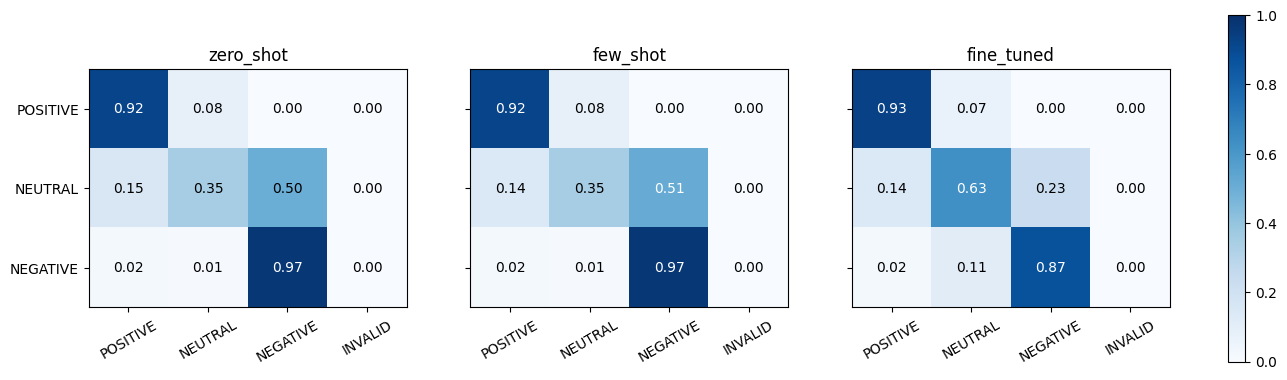

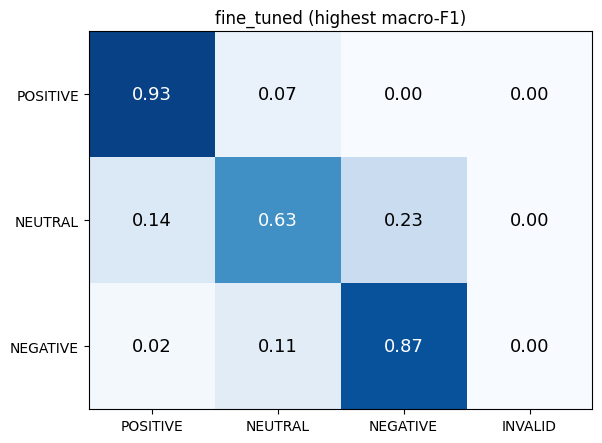

In [17]:
import matplotlib.pyplot as plt

fig, axes = plt.subplots(1, 3, figsize=(15, 4.5), sharey=True)
for ax, (n, m) in zip(axes, METRICS.items()):
    mat = np.array(normalize_rows(m["confusion"]))
    im = ax.imshow(mat, vmin=0, vmax=1, cmap="Blues")
    ax.set_title(n)
    ax.set_xticks(range(4)); ax.set_xticklabels(CM_COLUMNS, rotation=30)
    ax.set_yticks(range(3)); ax.set_yticklabels(LABELS)
    for i in range(3):
        for j in range(4):
            ax.text(j, i, f"{mat[i, j]:.2f}", ha="center", va="center", color="white" if mat[i, j] > 0.5 else "black")
fig.colorbar(im, ax=axes, fraction=0.02)
plt.savefig(OUT + "/confusion_three.png", dpi=120, bbox_inches="tight")
plt.show()
fig, ax = plt.subplots(figsize=(6.5, 5))
mat = np.array(normalize_rows(METRICS[BEST]["confusion"]))
ax.imshow(mat, vmin=0, vmax=1, cmap="Blues")
ax.set_title(f"{BEST} (highest macro-F1)")
ax.set_xticks(range(4)); ax.set_xticklabels(CM_COLUMNS); ax.set_yticks(range(3)); ax.set_yticklabels(LABELS)
for i in range(3):
    for j in range(4):
        ax.text(j, i, f"{mat[i, j]:.2f}", ha="center", va="center", color="white" if mat[i, j] > 0.5 else "black", fontsize=13)
plt.savefig(OUT + "/confusion_best.png", dpi=120, bbox_inches="tight")
plt.show()

In [18]:
MCNEMAR = pairwise_mcnemar(REF_BY_ID, PREDS)
for k, v in MCNEMAR.items():
    print(f"{k}: b={v['b']} c={v['c']} p={v['p']:.4f} (statsmodels {v['p_statsmodels']:.4f}, binomial cross-check {v['p_binomial']:.4f})")
print("Exact two-sided McNemar tests, three comparisons, no multiplicity adjustment applied.")
ERRORS = error_analysis(REF_BY_ID, PREDS["zero_shot"], PREDS["few_shot"], PREDS["fine_tuned"], n=10)
for k, v in ERRORS.items():
    print(k, "total", v["total"], "first ids", v["ids"])
COST = {"hosted_zero_shot": HOSTED_ZERO_COST, "hosted_few_shot": HOSTED_FEW_COST,
        "fine_tuned": {"train_seconds_own_timer": TRAIN_META["train_seconds"], "train_runtime_trainer": TRAIN_META["trainer_train_runtime"],
                       "peak_vram_train_gb": TRAIN_META["peak_vram_train_gb"], "peak_vram_infer_gb": PEAK_VRAM_INFER_GB,
                       "inference_seconds": FT_INFER_SECONDS, "adapter_zip_bytes": TRAIN_META["adapter_zip_bytes"]}}
print(json.dumps(COST, indent=1, default=str))

few_shot vs fine_tuned: b=12 c=31 p=0.0054 (statsmodels 0.0054, binomial cross-check 0.0054)
few_shot vs zero_shot: b=6 c=6 p=1.0000 (statsmodels 1.0000, binomial cross-check 1.0000)
fine_tuned vs zero_shot: b=34 c=15 p=0.0094 (statsmodels 0.0094, binomial cross-check 0.0094)
Exact two-sided McNemar tests, three comparisons, no multiplicity adjustment applied.
fixed_by_ft total 30 first ids [30030, 30094, 30102, 30143, 30381, 30671, 30834, 30849, 30934, 31357]
broken_by_ft total 10 first ids [30137, 30255, 30256, 30549, 30698, 31431, 31525, 31584, 31604, 31607]
wrong_in_all total 40 first ids [30008, 30011, 30024, 30038, 30061, 30064, 30078, 30184, 30290, 30384]
{
 "hosted_zero_shot": {
  "wall_s": 32.748330022000005,
  "calls": 300,
  "invalid": 0,
  "violations": 0
 },
 "hosted_few_shot": {
  "wall_s": 30.38427223100001,
  "calls": 300,
  "invalid": 0,
  "violations": 0
 },
 "fine_tuned": {
  "train_seconds_own_timer": 678.8423918579999,
  "train_runtime_trainer": 677.4314,
  "peak_v

In [19]:
# Star-word title rule: the Phase 2 regex STAR_TITLE (for example "Five Stars", "Great 5 stars"). INVALID counts as wrong.
# The reference-label mix differs between the two groups, so the within-class table is the like-for-like comparison.
TITLE_BY_ID = {e["filtered_index"]: e["title"] for e in EVAL_ITEMS}
STAR_TITLES = star_title_breakdown(REF_BY_ID, TITLE_BY_ID, PREDS)
print(f"star-word titles: {STAR_TITLES['n_star']} of {STAR_TITLES['n_star'] + STAR_TITLES['n_rest']} | reference labels "
      f"{STAR_TITLES['star_label_mix']} (other titles {STAR_TITLES['rest_label_mix']})")
_fmt = lambda x: "n/a" if x is None else f"{x:.4f}"
print(pd.DataFrame([{"approach": n, "star_title_correct": v["star_correct"], "star_title_accuracy": _fmt(v["star_accuracy"]),
                     "other_correct": v["rest_correct"], "other_accuracy": _fmt(v["rest_accuracy"])}
                    for n, v in STAR_TITLES["by_approach"].items()]).to_string(index=False))
print("\nwithin each reference class (recall = correct / reviews of that class in the group):")
print(pd.DataFrame([{"approach": n, "class": c, "star_n": d["star_n"], "star_correct": d["star_correct"],
                     "star_recall": _fmt(d["star_recall"]), "other_n": d["rest_n"], "other_correct": d["rest_correct"],
                     "other_recall": _fmt(d["rest_recall"])}
                    for n, v in STAR_TITLES["by_approach"].items() for c, d in v["per_class"].items()]).to_string(index=False))

star-word titles: 50 of 300 | reference labels {'POSITIVE': 29, 'NEUTRAL': 18, 'NEGATIVE': 3} (other titles {'POSITIVE': 71, 'NEUTRAL': 82, 'NEGATIVE': 97})
  approach  star_title_correct star_title_accuracy  other_correct other_accuracy
  few_shot                  42              0.8400            182         0.7280
fine_tuned                  50              1.0000            193         0.7720
 zero_shot                  39              0.7800            185         0.7400

within each reference class (recall = correct / reviews of that class in the group):
  approach    class  star_n  star_correct star_recall  other_n  other_correct other_recall
  few_shot POSITIVE      29            29      1.0000       71             63       0.8873
  few_shot  NEUTRAL      18            10      0.5556       82             25       0.3049
  few_shot NEGATIVE       3             3      1.0000       97             94       0.9691
fine_tuned POSITIVE      29            29      1.0000       71       

In [20]:
_re = read_predictions(PRED_PATH)
check_predictions_records(_re, EVAL_IDS)
_m2 = compute_metrics([r["reference_label"] for r in _re], [r["prediction"] for r in _re])
assert abs(_m2["macro_f1"] - METRICS["fine_tuned"]["macro_f1"]) < 1e-12 and abs(_m2["balanced_accuracy"] - METRICS["fine_tuned"]["balanced_accuracy"]) < 1e-12
assert _m2["confusion"] == METRICS["fine_tuned"]["confusion"]
print("C-21 PASS: fine-tuned metrics recomputed from the saved predictions file equal the displayed values")
for _n, _recs in (("zero_shot", HOSTED_ZERO_FILE), ("few_shot", HOSTED_FEW_FILE), ("fine_tuned", _re)):
    assert all(PREDS[_n][r["filtered_index"]] == parse_label(r["raw_response"]) for r in _recs)
print("predictions follow their raw responses for all three approaches")

C-21 PASS: fine-tuned metrics recomputed from the saved predictions file equal the displayed values
predictions follow their raw responses for all three approaches


In [21]:
FACTS = {
    "mode": MODE, "gpu": GPU_REPORT, "t4_tested_directly": "Tesla T4" in GPU_REPORT,
    "hosted_model": HOSTED["model"] + " (35B total, about 3B active)",
    "small_model": SM["load_id"], "trainable_params": TRAIN_META["trainable_params"], "total_params": TRAIN_META["total_params"],
    "lora_module_types": TRAIN_META["lora_module_types"], "model_dtype": TRAIN_META["model_dtype"],
    "fp16": TRAIN_META["fp16"], "bf16": TRAIN_META["bf16"], "hub_revisions": TRAIN_META["hub_revisions"],
    "training_settings": {k: TR[k] for k in TR}, "training_seconds": round(TRAIN_META["train_seconds"], 1),
    "generation_settings": {"hosted": {k: HOSTED[k] for k in ("temperature", "max_tokens", "extra_body")},
                            "fine_tuned": {k: SM[k] for k in ("max_new_tokens", "batch_size", "do_sample", "skip_special_tokens")}},
    "package_versions": package_versions(), "frozen_hash": FROZEN_HASH,
    "template_matches_hub": TRAIN_META["template_matches_hub"], "adapter_base_model_name_or_path": ADAPTER_CONFIG.get("base_model_name_or_path"),
    "metrics": {n: {"balanced_accuracy": m["balanced_accuracy"], "macro_f1": m["macro_f1"], "invalid": m["invalid"]} for n, m in METRICS.items()},
    "mcnemar": {k: {"b": v["b"], "c": v["c"], "p": v["p"]} for k, v in MCNEMAR.items()},
    # rebuilt from the saved file, so a restart before S10 cannot lose it; cost is the sum of per-call latencies
    "hosted_flip_rate_train": {"design": "3 back-to-back calls per TRAIN prompt in one run (short-term repeatability)",
                               "seed": FLIP["seed"], "repeats": FLIP["repeats"],
                               "by_approach": flip_summary(read_jsonl(OUT + "/hosted_flip_rate_raw.jsonl"), FLIP["approaches"])},
    "star_word_titles": {k: STAR_TITLES[k] for k in ("n_star", "n_rest", "star_label_mix", "rest_label_mix", "by_approach")},
}
print(json.dumps(FACTS, indent=1, default=str))
with open(OUT + "/report_facts.json", "w") as f:
    json.dump(FACTS, f, indent=1, default=str)
persist(OUT + "/report_facts.json")

{
 "mode": "final",
 "gpu": "Tesla T4, 15360 MiB, 580.82.07",
 "t4_tested_directly": true,
 "hosted_model": "cyankiwi/Qwen3.6-35B-A3B-AWQ-4bit (35B total, about 3B active)",
 "small_model": "unsloth/gemma-3-4b-it",
 "trainable_params": 29802496,
 "total_params": 4329881968,
 "lora_module_types": [
  "down_proj",
  "gate_proj",
  "k_proj",
  "o_proj",
  "q_proj",
  "up_proj",
  "v_proj"
 ],
 "model_dtype": "torch.float16",
 "fp16": false,
 "bf16": false,
 "hub_revisions": {
  "unsloth/gemma-3-4b-it": "bf46152c47f5dd20b896357cb51abc4c03b8ee8c",
  "unsloth/gemma-3-4b-it-unsloth-bnb-4bit": "316726ca0bd24aa323bfaf86e8a379ee1176d1fe"
 },
 "training_settings": {
  "r": 16,
  "lora_alpha": 16,
  "lora_dropout": 0,
  "bias": "none",
  "finetune_vision_layers": false,
  "finetune_language_layers": true,
  "finetune_attention_modules": true,
  "finetune_mlp_modules": true,
  "expected_lora_modules": [
   "q_proj",
   "k_proj",
   "v_proj",
   "o_proj",
   "gate_proj",
   "up_proj",
   "down_proj"

*Authorship note: the assistant (Claude) drafted this report at my request. Its numbers were checked by script against the notebook's saved outputs and result files.*

# S10 Report

**What I compared.** Three ways of labeling 300 Amazon Gift Cards reviews (100 per class) as POSITIVE, NEUTRAL or NEGATIVE, using star ratings as the answer key (4 or 5 stars positive, 3 neutral, 1 or 2 negative). The first two use a large hosted model, Qwen3.6-35B-A3B (35 billion parameters, about 3 billion active at a time): once with no examples and once shown 6 examples. The third is a small model I trained myself, Gemma 3 4B (4,329,881,968 parameters, of which 29,802,496 were adjusted through a small add-on called an adapter, on a compressed 4-bit copy of the model, using Unsloth). Training ran on a Tesla T4 GPU, tested directly, for 114 steps over 2 passes through 900 training reviews, and took 678.8 seconds (about 11 minutes).

**Why these choices.** The small model had to fit a T4; Gemma 3 4B used 5.15 GB during training. Training settings start from Unsloth's documented example (rank 16, learning rate 0.0002, seed 3407); the 16 reviews per step and the 2 passes were my choices, because the documentation is not consistent on them. The 6 examples are training reviews, the first 2 per class from a shortlist built by a fixed rule (150 to 450 characters, no "Five Stars" titles). Two are noisy: review 13547 has 4 stars but describes a confusing reload, and 9272 has 1 star but reads like a neutral question. No test review was used.

**Results** (300 test reviews, no invalid answers). Balanced accuracy is the average share of each class found correctly; macro-F1 is a similar average that also penalizes wrong guesses.

| Approach | Balanced accuracy | Macro-F1 | Correct / incorrect | NEUTRAL recall |
|---|---|---|---|---|
| Hosted, no examples | 0.747 | 0.717 | 224 / 76 | 0.35 |
| Hosted, 6 examples | 0.747 | 0.718 | 224 / 76 | 0.35 |
| Fine-tuned Gemma 3 4B | 0.810 | 0.805 | 243 / 57 | 0.63 |

**Best approach, and where it fails.** The fine-tuned model scored highest, mostly on NEUTRAL reviews: the hosted model called 50 (no examples) or 51 (6 examples) of 100 neutral reviews negative, the fine-tuned model 23. Review 30030 ("Ok but I won't do it again", 3 stars) was called negative by both hosted runs and neutral by the fine-tuned model. Its weakness is the other direction: it called 11 of 100 negative reviews neutral, against 1 for the hosted model with no examples, for example review 30137 ("Not Amazons Usual Excellence", 1 star). All three missed review 30008 (a 3-star pop-up complaint, called negative) and review 30011 (title and text both "Gift", 5 stars, called neutral).

**A caution about titles.** 50 reviews have titles like "Five Stars", which give the rating away. The fine-tuned model got all 50 right (the hosted runs 39 and 42). The notebook's own breakdown by title type shows its lead shrinks on the other 250 reviews: 193 correct, against 185 and 182.

**What the statistics support.** A McNemar test counts only the reviews where exactly one of two approaches is right. The fine-tuned model was right alone on 34 reviews against 15 for the hosted model with no examples (p = 0.0094), and on 31 against 12 versus 6 examples (p = 0.0054). The p-value is how likely so lopsided a split would be if both approaches were equally accurate; a small value is evidence of a real difference on these reviews, not a measure of how big or how useful it is. The two hosted runs split 6 and 6 (p = 1.0): the examples left no net difference. A follow-up calculation outside this notebook, repeating the tests without the 50 star-word reviews, gave p = 0.26 and p = 0.09, so the gap is no longer clear there. Limits: one dataset, one small model, one set of 6 examples, one run each; the hosted model is far larger; star ratings are a noisy answer key, especially at 3 stars. In the final run, 238 of 300 hosted no-example answers came from an earlier attempt that stopped on a file error.

**Is the gain worth the cost?** Fine-tuning took 678.8 seconds on one T4, produced a 110 MB adapter, and needed 900 labeled reviews. Labeling the 300 test reviews then took 141.6 seconds on that T4 using 6.23 GB, against 30.4 seconds for 300 few-shot requests to the hosted model, which needs a remote service but no training. The fine-tuned model scored 0.063 higher in balanced accuracy, but much of that lead is in the star-word titles. My answer: for a one-off job of 300 reviews, no, the hosted model is cheaper and the gain is not firm. Fine-tuning would be worth it if reviews had to be labeled again and again on a small GPU without a remote service, and if the gain held up on a fresh sample.

**A decision I investigated with my agent.** My first small model, Phi-4-mini, trained only 8,912,896 parameters in a trial run. The agent showed this was exactly 2 of the model's 4 kinds of layers, because Unsloth did not recognize its combined layer names, and a retest gave the same result. It offered three options (keep the weaker adapter, work around Unsloth, switch models) and recommended Gemma 3 4B. I made the choice: the switch (option A) over keeping the weaker two-layer adapter (B) or working around Unsloth (C). B would have evaluated an adapter weaker than the one I approved, C meant custom code outside Unsloth's supported path, and A had a documented Unsloth recipe for Gemma 3 4B . A new check in the notebook, which fails unless all 7 kinds of layers are trained, passed with Gemma 3 4B (238 trained modules), and the reloaded saved adapter reproduced its predictions. One consequence: the model the adapter was trained on, and must be loaded with, is unsloth/gemma-3-4b-it-unsloth-bnb-4bit, Unsloth's 4-bit build of google/gemma-3-4b-it, and adapter_config.json names exactly that id. The Google original requires access approval.